## Семинар по теме «Линейная регрессия»


Рассмотрим, как на практике работает линейная регрессия и что влияет на её качество. Это поможет тебе понять, как поведение модели зависит от масштаба признаков и структуры данных.

Из этого семинара ты узнаешь:

- почему аналитическое решение линейной регресии нестабильно.

- как бороться с проблемами мультиколлинеарности с помощью регуляризации.

- почему необходимо нормировать признаки для корректной работы регуляризации.



## Подготовка

### Импорт библиотек и загрузка данных

In [112]:
import pandas as pd
import numpy as np

import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt


from IPython.display import display

Возьмем данные из соревнования [House Prices: Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques/overview). Задача — предсказать цену дома по 79 характеристикам.

In [ ]:
# Загружаем данные
! gdown 1SKx5Shx5J1O45mKBmjCtQmUF7LXRUou-

In [113]:
data = pd.read_csv("./train.csv")
data.head()
print(f'Shape data: {data.shape}')

Shape data: (1460, 81)


Для максимально качественного решения задачи нужно понимать, что обозначает каждый признак. Но сегодня мы лишь рассмотрим техники, которые применяют для обучения линейной регрессии, и не будем добиваться максимального качества.

Подробное описание признаков датасета: [файл 1](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data?select=test.csv), [файл 2](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data?select=data_description.txt).

<!-- Но если интересно, описание признаков можно [посмотреть вот тут](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data?select=test.csv) и [тут](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data?select=data_description.txt). -->

### Анализ данных

<!-- Как всегда, небольшой ресерч данных -->

In [114]:
# Описываем признаки датасета: тип столбца и количество пропусков
def get_dataset_info(data):
    dt_dtypes = pd.DataFrame(data.dtypes)
    dt_dtypes.columns = ["dtype"]

    dt_nulls = pd.DataFrame(data.isnull().sum())
    dt_nulls.columns = ["nulls"]

    dt_nunique = pd.DataFrame(data.nunique())
    dt_nunique.columns = ["nunuqie"]

    return dt_dtypes.join(dt_nulls).join(dt_nunique).T

# Объединяем со стандарным методом для получения описательных статистик
def full_describe(data):
    return pd.concat([get_dataset_info(data), data.describe()])

In [115]:
# Используем контекстный менеджер, чтобы удобно вывести все столбцы
with pd.option_context('display.max_columns', len(data.columns)):
  display(get_dataset_info(data))

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
dtype,int64,int64,object,float64,int64,object,object,object,object,object,object,object,object,object,object,object,object,int64,int64,int64,int64,object,object,object,object,object,float64,object,object,object,object,object,object,object,int64,object,int64,int64,int64,object,object,object,object,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,object,int64,object,int64,object,object,float64,object,int64,int64,object,object,object,int64,int64,int64,int64,int64,int64,object,object,object,int64,int64,int64,object,object,int64
nulls,0,0,0,259,0,0,1369,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,872,8,0,0,0,37,37,38,37,0,38,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,690,81,81,81,0,0,81,81,0,0,0,0,0,0,0,1453,1179,1406,0,0,0,0,0,0
nunuqie,1460,15,5,110,1073,2,2,4,4,2,5,3,25,9,8,5,8,10,9,112,61,6,8,15,16,3,327,4,5,6,4,4,4,6,637,6,144,780,721,6,5,2,5,753,417,24,861,4,3,4,3,8,4,4,12,7,4,5,6,97,3,5,441,5,5,3,274,202,120,20,76,8,3,4,4,21,12,5,9,6,663


Посмотрим, сколько категорий получилось.

In [116]:
dt_dtypes = pd.DataFrame(data.dtypes)
dt_dtypes.columns = ["dtype"]

In [117]:
dt_dtypes.value_counts()

dtype  
object     43
int64      35
float64     3
Name: count, dtype: int64

Достаточно много категориальных признаков для решения задачи.

**Вопрос.** Может ли линейная регрессия работать с категориальными признаками?

Выберем пока только числовые признаки, с категориальными признаками поработаем во второй части семинара.

In [118]:
data_numeric = data.select_dtypes(include='number').copy()
print(f'Shape data_numeric: {data_numeric.shape}')

Shape data_numeric: (1460, 38)


In [119]:
with pd.option_context('display.max_columns', len(data_numeric.columns)):
  display(full_describe(data_numeric))

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
dtype,int64,int64,float64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
nulls,0,0,259,0,0,0,0,0,8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,81,0,0,0,0,0,0,0,0,0,0,0,0
nunuqie,1460,15,110,1073,10,9,112,61,327,637,144,780,721,753,417,24,861,4,3,4,3,8,4,12,4,97,5,441,274,202,120,20,76,8,21,12,5,663
count,1460.0,1460.0,1201.0,1460.0,1460.0,1460.0,1460.0,1460.0,1452.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1379.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0
mean,730.5,56.89726,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.95411,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.19589
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.0,20.0,21.0,1300.0,1.0,1.0,1872.0,1950.0,0.0,0.0,0.0,0.0,0.0,334.0,0.0,0.0,334.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,1900.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2006.0,34900.0
25%,365.75,20.0,59.0,7553.5,5.0,5.0,1954.0,1967.0,0.0,0.0,0.0,223.0,795.75,882.0,0.0,0.0,1129.5,0.0,0.0,1.0,0.0,2.0,1.0,5.0,0.0,1961.0,1.0,334.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2007.0,129975.0
50%,730.5,50.0,69.0,9478.5,6.0,5.0,1973.0,1994.0,0.0,383.5,0.0,477.5,991.5,1087.0,0.0,0.0,1464.0,0.0,0.0,2.0,0.0,3.0,1.0,6.0,1.0,1980.0,2.0,480.0,0.0,25.0,0.0,0.0,0.0,0.0,0.0,6.0,2008.0,163000.0
75%,1095.25,70.0,80.0,11601.5,7.0,6.0,2000.0,2004.0,166.0,712.25,0.0,808.0,1298.25,1391.25,728.0,0.0,1776.75,1.0,0.0,2.0,1.0,3.0,1.0,7.0,1.0,2002.0,2.0,576.0,168.0,68.0,0.0,0.0,0.0,0.0,0.0,8.0,2009.0,214000.0


Посмотрим, что обозначают те признаки, в которых есть пропуски. Также убедимся, что сюда не попали категориальные признаки: под подозрение попадают те, в которых мало уникальных значений.

`Id` —  метапризнак, который показывает id наблюдения. Он не нужен для решения, можно удалить.

`MSSubClass` —  тип здания. Категориальный.

`LotFrontage` —  длина прилегающей улицы. Пропуски можно заменить средним значением.

`OverallQual` —  оценка качества материалов здания. Оставляем числовым, так как можем сравнивать значения между собой.

`OverallCond` —  оценка качества здания в целом. Оставляем числовым, так как можем сравнивать значения между собой.

`YearBuilt` —  год постройки здания.

`LowQualFinSF` —  квадратные метры с отделкой низкого качества (все этажи).

`BsmtFullBath`, `BsmtHalfBath`, `FullBath`, `HalfBath` —  описание (полу)ванных комнат.

`BedroomAbvGr`, `KitchenAbvGr`, `TotRmsAbvGrd`, `Fireplaces`, `GarageCars` — количество разных комнат, каминов и вместимость гаража.

`3SsnPorch` — площадь трёхсезонной веранды в квадратных футах.

`PoolArea`, `MiscVal`, `MoSold`, `YrSold` —  площадь бассейна, стоимость разных объектов на участке, месяц и год продажи.

`MasVnrArea` — площадь облицовки каменной кладки в квадратных футах. Пропуски заменяем на среднее значение.

`GarageYrBlt` — год постройки гаража. Пропуски заменяем на среднее значение.



In [120]:
# Сохраняем исходные числовые данные: позже пропуски будут заполняться внутри CV
data_numeric_raw = data_numeric.drop(['MSSubClass', 'Id'], axis=1).copy()

# Используем то же разбиение, что и далее. Средние считаем только по train
from sklearn.model_selection import train_test_split
train_indices, _ = train_test_split(data_numeric.index, test_size=0.25, random_state=42)
for col in ["LotFrontage", "MasVnrArea", "GarageYrBlt"]:
    train_mean = data_numeric.loc[train_indices, col].mean()
    data_numeric.fillna({col: train_mean}, inplace=True)

# Исключаем категориальный признак MSSubClass и ID
data_numeric.drop(['MSSubClass', 'Id'], axis=1, inplace=True)

In [121]:
data['MSSubClass'] = data['MSSubClass'].astype(str)
data_object = data.select_dtypes(exclude='number')

In [122]:
# Категориальную переменную исключили, и пропусков больше нет
with pd.option_context('display.max_columns', len(data_numeric.columns)):
  display(full_describe(data_numeric))

,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
dtype,float64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
nulls,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
nunuqie,111,1073,10,9,112,61,328,637,144,780,721,753,417,24,861,4,3,4,3,8,4,12,4,98,5,441,274,202,120,20,76,8,21,12,5,663
count,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0
mean,70.111064,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.683526,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.516602,1.767123,472.980137,94.244521,46.660274,21.95411,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.19589
std,22.024416,9981.264932,1.382997,1.112799,30.202904,20.645407,180.569114,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,23.994622,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,21.0,1300.0,1.0,1.0,1872.0,1950.0,0.0,0.0,0.0,0.0,0.0,334.0,0.0,0.0,334.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,1900.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2006.0,34900.0
25%,60.0,7553.5,5.0,5.0,1954.0,1967.0,0.0,0.0,0.0,223.0,795.75,882.0,0.0,0.0,1129.5,0.0,0.0,1.0,0.0,2.0,1.0,5.0,0.0,1962.0,1.0,334.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2007.0,129975.0
50%,70.394413,9478.5,6.0,5.0,1973.0,1994.0,0.0,383.5,0.0,477.5,991.5,1087.0,0.0,0.0,1464.0,0.0,0.0,2.0,0.0,3.0,1.0,6.0,1.0,1978.694311,2.0,480.0,0.0,25.0,0.0,0.0,0.0,0.0,0.0,6.0,2008.0,163000.0
75%,79.0,11601.5,7.0,6.0,2000.0,2004.0,164.25,712.25,0.0,808.0,1298.25,1391.25,728.0,0.0,1776.75,1.0,0.0,2.0,1.0,3.0,1.0,7.0,1.0,2001.0,2.0,576.0,168.0,68.0,0.0,0.0,0.0,0.0,0.0,8.0,2009.0,214000.0


In [123]:
# Посмотрим на категориальные переменные, с ними будем работать позже
with pd.option_context('display.max_columns', len(data_object.columns)):
  display(full_describe(data_object))

,MSSubClass,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,Heating,HeatingQC,CentralAir,Electrical,KitchenQual,Functional,FireplaceQu,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
dtype,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object
nulls,0,0,0,1369,0,0,0,0,0,0,0,0,0,0,0,0,0,0,872,0,0,0,37,37,38,37,38,0,0,0,1,0,0,690,81,81,81,81,0,1453,1179,1406,0,0
nunuqie,15,5,2,2,4,4,2,5,3,25,9,8,5,8,6,8,15,16,3,4,5,6,4,4,4,6,6,6,5,2,5,4,7,5,6,3,5,5,3,3,4,4,9,6
count,1460,1460,1460,91,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,588,1460,1460,1460,1423,1423,1422,1423,1422,1460,1460,1460,1459,1460,1460,770,1379,1379,1379,1379,1460,7,281,54,1460,1460
unique,15,5,2,2,4,4,2,5,3,25,9,8,5,8,6,8,15,16,3,4,5,6,4,4,4,6,6,6,5,2,5,4,7,5,6,3,5,5,3,3,4,4,9,6
top,20,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,Gable,CompShg,VinylSd,VinylSd,BrkFace,TA,TA,PConc,TA,TA,No,Unf,Unf,GasA,Ex,Y,SBrkr,TA,Typ,Gd,Attchd,Unf,TA,TA,Y,Gd,MnPrv,Shed,WD,Normal
freq,536,1151,1454,50,925,1311,1459,1052,1382,225,1260,1445,1220,726,1141,1434,515,504,445,906,1282,647,649,1311,953,430,1256,1428,741,1365,1334,735,1360,380,870,605,1311,1326,1340,3,157,49,1267,1198


Заполним пропуски отдельной категорией «No data» (нет данных).

In [124]:
data_object.fillna('No data', inplace=True)

Построим график с распределением целевой переменной.

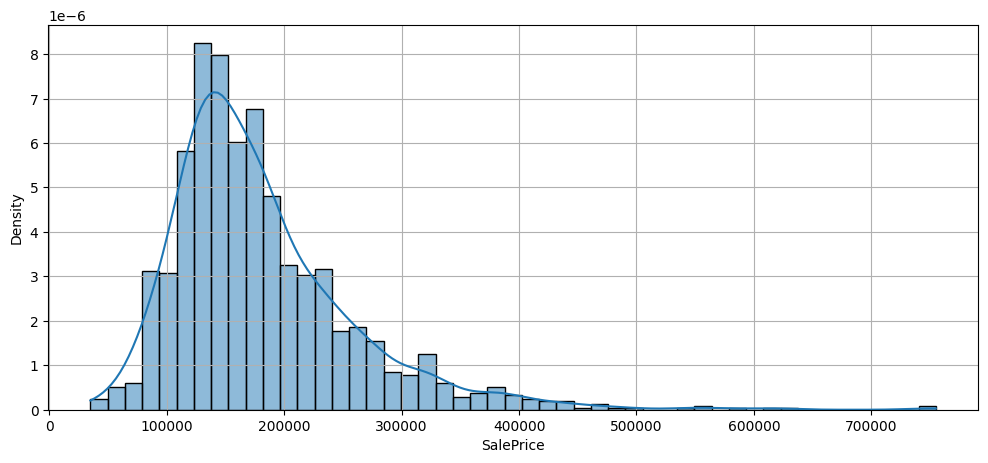

In [125]:
fig, ax = plt.subplots(figsize=(12, 5))
corr = data_numeric.corr()
sns.histplot(data_numeric['SalePrice'], kde=True, stat="density", ax=ax)
plt.grid()

Судя по гистограмме, в данных есть примеры с нетипично большой стоимостью. Это может помешать вычислениям, если функция потерь слишком чувствительна к выбросам. В дальнейшем мы рассмотрим способы, как минимизировать ущерб от этого.

## Линейная регрессия в sklearn

Обучим линейную регрессию на числовых признаках из нашего датасета.
В sklearn реализовано несколько вариантов линейной регресcии:

1) [`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html#sklearn.linear_model.LinearRegression) — «классическая» линейная регрессия с функцией потерь MSE.

2) [`Ridge`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) — линейная регрессия с функцией потерь в виде суммы MSE и L2-регуляризациии.


3) [`Lasso`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html#sklearn.linear_model.Lasso) — линейная регрессия с функцией в виде суммы MSE и L1-регуляризациии.


4) [`ElasticNet`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) — линейная регрессия с функцией потерь в виде суммы MSE и одновременно L1 и L2-регуляризацией.


### Аналитическое решение

Повторим теорию.

В матрице $X$ строки соответствуют объектам, столбцы признакам. Добавим столбец единиц для свободного члена. При $n$ объектах и $p$ исходных признаках размер $X$ равен $n \times (p + 1)$. Размерность вектора коэффициентов $w$ равна $p + 1$, а вектор $y$ содержит $n$ ответов.

Например, для одного признака строка $[1, 50]$ и коэффициенты $[10, 2]$ дают прогноз $1 \cdot 10 + 50 \cdot 2 = 110$. Первый коэффициент задаёт свободный член. Умножение $Xw$ выполняет такой расчёт сразу для всех строк.

Соберём такую матрицу для восьми домов: столбец единиц и жилая площадь.

In [126]:
# Матрица X для 8 домов: столбец единиц и площадь
toy = data.sample(8, random_state=1)
ones = np.ones((len(toy), 1))
area = toy[["GrLivArea"]].values

X_toy = np.hstack([ones, area])
y_toy = toy["SalePrice"].values / 1e3          # цена, тыс. $

In [130]:
y_toy

array([231.5  , 179.5  , 122.   ,  84.5  , 142.   , 325.624, 285.   ,
       151.   ])

In [129]:
X_toy

array([[1.000e+00, 1.792e+03],
       [1.000e+00, 2.192e+03],
       [1.000e+00, 9.000e+02],
       [1.000e+00, 6.300e+02],
       [1.000e+00, 1.188e+03],
       [1.000e+00, 2.161e+03],
       [1.000e+00, 2.374e+03],
       [1.000e+00, 1.200e+03]])

In [127]:
X_toy

array([[1.000e+00, 1.792e+03],
       [1.000e+00, 2.192e+03],
       [1.000e+00, 9.000e+02],
       [1.000e+00, 6.300e+02],
       [1.000e+00, 1.188e+03],
       [1.000e+00, 2.161e+03],
       [1.000e+00, 2.374e+03],
       [1.000e+00, 1.200e+03]])

Модель линейной регрессии записывается как:

$$\hat y = X w.$$

Цель найти такие коэффициенты $w$, чтобы прогнозы $\hat y$ были как можно ближе к настоящим ответам $y$. Разница $e_i = y_i - \hat y_i$ называется **остатком**. На графике это вертикальный отрезок от точки до прямой: мы измеряем ошибку прогноза цены, а не расстояние до прямой.

Качество всей прямой оценивается суммой квадратов остатков $\|Xw - y\|^2$. Это функция ошибки, и её нужно минимизировать по $w$:

$$\|Xw - y\|^2 \rightarrow \min_w.$$

Посмотрим на две прямые, выбранные наугад.

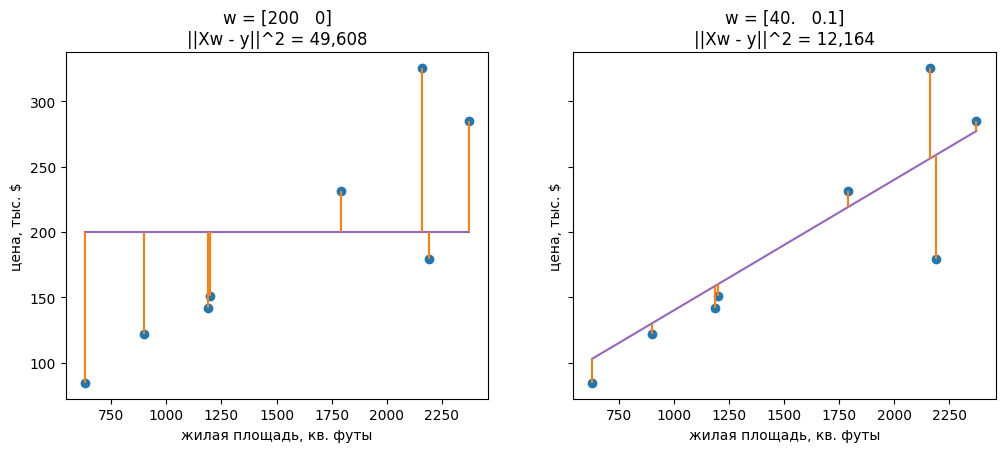

In [131]:
def draw_residuals(ax, w):
    """Прямая y = w0 + w1*x, остатки-отрезки и сумма квадратов остатков."""
    x = X_toy[:, 1]
    
    prediction = X_toy @ w
    loss = ((prediction - y_toy)**2).sum()
    ends = np.array([x.min(), x.max()])

    ax.scatter(x, y_toy)
    ax.plot(ends, w[0] + w[1] * ends, color="tab:purple")
    ax.vlines(x, prediction, y_toy, color="tab:orange")
    ax.set(xlabel="жилая площадь, кв. футы", ylabel="цена, тыс. $",
           title=f"w = {np.round(w, 3)}\n||Xw - y||^2 = {loss:,.0f}")


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, w in zip(axes, [np.array([200, 0]), np.array([40, 0.1])]):
    draw_residuals(ax, w)

plt.show()

In [132]:
X_toy.shape

(8, 2)

**Вывод формулы.** Раскроем квадрат нормы. По определению $\|a\|^2 = a^T a$, поэтому

$$\|Xw - y\|^2 = (Xw - y)^T (Xw - y) = w^T X^T X w - w^T X^T y - y^T X w + y^T y.$$

Два средних слагаемых равны между собой (это числа, а не матрицы), поэтому их можно сложить. Приравняем градиент к нулю:

$$\nabla_w \|Xw - y\|^2 = 2 X^T X w - 2 X^T y = 0.$$

Отсюда получаем нормальное уравнение:

$$X^T X w = X^T y.$$

Если матрица $X^T X$ обратима, умножим обе части слева на $(X^T X)^{-1}$:

$$w = (X^T X)^{-1} X^T y.$$

Это и есть аналитическое решение задачи линейной регрессии. Соберём его по шагам на тех же восьми домах.

In [133]:
# Собираем формулу w = (X^T X)^(-1) X^T y на наших восьми домах.
# Нормальное уравнение: left @ w = right

left = X_toy.T @ X_toy                    # X^T X
right = X_toy.T @ y_toy                # X^T y

w_hat = np.linalg.inv(left) @ right                  # решаем уравнение относительно w
w_hat

array([18.24026398,  0.11057344])

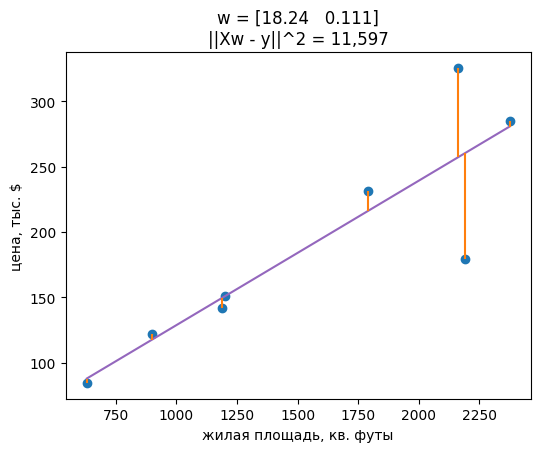

In [134]:
fig, ax = plt.subplots(figsize=(6, 4.5))
draw_residuals(ax, w_hat)
plt.show()

*  Далее обучим обычную линейную регрессию на численных признаках и посмотрим на качество.

* Как метрику качества возьмем `RMSE`, корень из `MSE`, чтобы посмотреть, насколько мы ошибаемся в абсолютных величинах.
* Для обучения модели используем формулу весов, полученную аналитически.

In [135]:
# Реализация линейной регрессии из sklearn нам пригодится, чтобы сравнить результаты нашего решения с эталонным
from sklearn.linear_model import LinearRegression
# Метрики, которые нам понадобятся, поговорим про них позже
from sklearn.metrics import root_mean_squared_error, mean_absolute_percentage_error

#### Задание 1

Напиши функцию, которая вычисляет линейную регрессию через аналитическю формулу (дана выше).
Не забудь добавить вектор из единиц к данным, чтобы включить константу в модель.

In [136]:
# Напиши код здесь
def solve_linear_regression(X, y):
  X_ones = np.hstack([np.ones((len(X), 1)), X])

  left = X_ones.T @ X_ones                    # X^T X
  right = X_ones.T @ y              # X^T y

  w_hat = np.linalg.inv(left) @ right                  
  return w_hat

<!-- Теперь попробуем решить нашу задачу. -->
Перейдём к поиску решения линейной регрессии для нашего датасета.

In [137]:
# Для начала разобъём выборку на обучающую и валидационную
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(
        data_numeric.drop(["SalePrice"], axis=1), data_numeric['SalePrice'],
        test_size=0.25, random_state=42
)

**Вопрос.** Зачем фиксировать `random_state`?

In [138]:
%%time
regr = LinearRegression()

regr.fit(X_train, y_train)

CPU times: total: 688 ms
Wall time: 125 ms


LinearRegression()

In [139]:
print(f"Coef. :{regr.intercept_,}")
print(f"Coef. :{regr.coef_,}")

Coef. :(-868340.4825431794,)
Coef. :(array([-2.07076938e+01,  4.54700255e-01,  1.70188548e+04,  4.05741611e+03,
        2.62813293e+02,  1.59603358e+02,  2.11772320e+01,  8.66570263e+00,
       -1.59385837e+00,  2.36806586e-01,  7.30865084e+00,  1.83039187e+01,
        1.15953113e+01, -3.95382636e+00,  2.59454037e+01,  1.01667092e+04,
       -2.45780646e+03,  1.88799445e+03, -1.80262889e+03, -6.99171824e+03,
       -2.67680840e+04,  6.19058064e+03,  4.71557163e+03,  1.17479515e+02,
        1.28813814e+04,  6.74130682e-01,  2.15556925e+01, -7.82219443e+00,
        5.74111347e+00,  5.23033541e+01,  6.50636430e+01, -2.60337559e+01,
       -1.90341178e+00,  5.33074962e+01, -1.27009723e+02]),)


Попробуем найти решение с помощью формул из линейной алгебры.

In [140]:
X, y = X_train.values, y_train.values
coef_reg = solve_linear_regression(X, y)

print(f"Coef. :{coef_reg}")

Coef. :[-2.12681441e+07  3.31726287e+04 -1.40329513e+01 -4.73966611e+05
 -1.11850886e+05  7.40093122e+03  3.67230134e+03  8.93094063e+01
  3.41518744e+15  3.41518744e+15  3.41518744e+15 -3.41518744e+15
  1.02400000e+03  7.68000000e+02  2.56000000e+02  2.56000000e+02
  1.01667092e+04 -2.45780647e+03  1.88799444e+03 -1.80262889e+03
 -6.99171824e+03 -2.67680840e+04  6.19058064e+03  4.71557163e+03
  1.17479515e+02  1.28813814e+04  6.74130674e-01  2.15556925e+01
 -7.82219443e+00  5.74111347e+00  5.23033541e+01  6.50636430e+01
 -2.60337559e+01 -1.90341178e+00  5.33074962e+01 -1.27009724e+02]


Глазами два списка из 35 чисел не сравнить. Соберём их в таблицу и отсортируем по разнице.

In [141]:
def compare_coefficients(sklearn_model, manual_weights, feature_names):
    """Сравнивает коэффициенты sklearn и ручного решения. Первый вес ручного это свободный член."""
    table = pd.DataFrame({
        "sklearn": np.append(sklearn_model.intercept_, sklearn_model.coef_),
        "вручную": manual_weights,
    }, index=np.append("(свободный член)", feature_names))

    table["разница"] = (table["вручную"] - table["sklearn"]).abs()
    return table.sort_values("разница", ascending=False)


comparison = compare_coefficients(regr, coef_reg, X_train.columns)
comparison.head(8)

,sklearn,вручную,разница
BsmtFinSF2,-1.593858,3.415187e+15,3.415187e+15
BsmtUnfSF,0.236807,3.415187e+15,3.415187e+15
BsmtFinSF1,8.665703,3.415187e+15,3.415187e+15
TotalBsmtSF,7.308651,-3.415187e+15,3.415187e+15
(свободный член),-868340.482543,-2.126814e+07,2.039980e+07
OverallQual,17018.854791,-4.739666e+05,4.909855e+05
OverallCond,4057.416114,-1.118509e+05,1.159083e+05
LotFrontage,-20.707694,3.317263e+04,3.319334e+04


In [142]:
print("совпали до 6 знаков:", (comparison["разница"] < 1e-6).sum(), "из", len(comparison))
print("максимальный коэффициент sklearn: {:.3g}".format(comparison["sklearn"].abs().max()))
print("максимальный коэффициент вручную: {:.3g}".format(comparison["вручную"].abs().max()))

совпали до 6 знаков: 16 из 36
максимальный коэффициент sklearn: 8.68e+05
максимальный коэффициент вручную: 3.42e+15


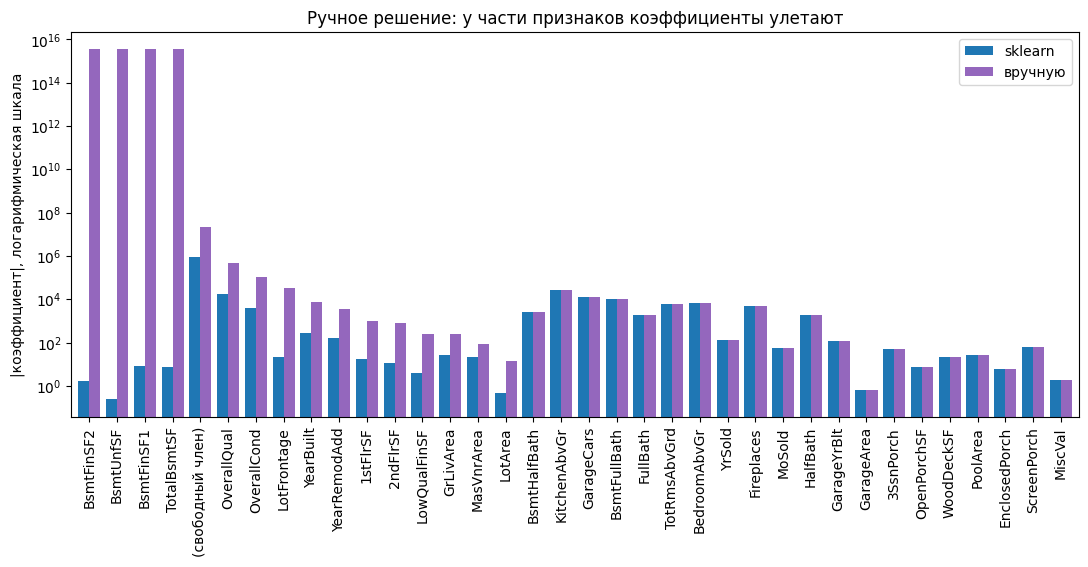

In [143]:
sizes = comparison[["sklearn", "вручную"]].abs()

ax = sizes.plot.bar(logy=True, width=.8, figsize=(13, 5), color=["tab:blue", "tab:purple"])
ax.set(ylabel="|коэффициент|, логарифмическая шкала",
       title="Ручное решение: у части признаков коэффициенты улетают")
plt.show()

Коэффициенты для модели sklearn и точного решения для линейной регрессии совпадают лишь отчасти. В реализации sklearn нет очень больших значений, в то время как в нашей ручной реализации есть вплоть до 14-й степени. При этом значения коэффициентов у больших переменных совпадают.

Почему это могло произойти?

Почему тогда у реализации линейной регрессии из sklearn нет настолько больших коэффициентов?

Оценим, как работает линейная регрессия из sklearn. Для этого посчитаем метрики `Train RMSE` и `Val RMSE`:

In [144]:
# Получаем предсказания модели, а потом вычисляем метрику
rmse_train = root_mean_squared_error(regr.predict(X_train), y_train)
rmse_valid = root_mean_squared_error(regr.predict(X_val), y_val)

print(f"Train RMSE: {rmse_train:.1f}")
print(f"Val RMSE:   {rmse_valid:.1f}")

Train RMSE: 35170.9
Val RMSE:   34927.6



Насколько корректно оценивать модели с помощью RMSE с учётом того, что оптимизация линейной регрессии происходит по MSE?

[Подробнее об оптимизации MSE vs. RMSE](https://stats.stackexchange.com/questions/532414/rmse-vs-mse-loss-function-the-optimization-solutions-are-equivalent).

Сильно ли ошибается модель?

In [145]:
# Эта таблица поможет тебе с ответом
y_train.describe()

count      1095.000000
mean     181712.286758
std       77955.082565
min       34900.000000
25%      130000.000000
50%      165000.000000
75%      215000.000000
max      745000.000000
Name: SalePrice, dtype: float64

Чтобы каждый раз не оценивать, насколько сильно мы относительно масштаба ошиблись, придумали метрику MAPE (англ. mean absolute percentage error). Она показывает, насколько в процентах мы ошиблись относительно эталонного предсказания.

$MAPE = \frac{1}{n}\sum_{i=1}^{n}\frac{|y_i-\hat y_i|}{|y_i|}$.

В sklearn MAPE возвращается как доля: например, 0,15 соответствует 15%.

С чем может быть связана проблема с такой метрикой?

Теперь посчитаем:
- `Train RMSE`.
- `Val RMSE`.
- `Train MAPE`.
- `Val MAPE`.

In [146]:
# Получаем предсказания
preds_train = regr.predict(X_train)
preds_valid = regr.predict(X_val)

# train / valid RMSE, как раньше
rmse_train = root_mean_squared_error(preds_train, y_train)
rmse_valid = root_mean_squared_error(preds_valid,   y_val)

# Вычисляем MAPE
mape_train = mean_absolute_percentage_error(y_train, preds_train)
mape_valid = mean_absolute_percentage_error(y_val, preds_valid)

print(f"Train RMSE: {rmse_train:.1f}")
print(f"Val   RMSE: {rmse_valid:.1f}")
print(f"Train MAPE: {mape_train:.3f}")
print(f"Val   MAPE: {mape_valid:.3f}")


Train RMSE: 35170.9
Val   RMSE: 34927.6
Train MAPE: 0.128
Val   MAPE: 0.130


In [147]:
# Создаём контейнер для хранения информации о метриках
res = {}

# Запишем метрики в наш контейнейр и выведем таблицу
res['base'] = [rmse_train, rmse_valid, mape_train, mape_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmse_train', 'rmse_valid', 'mape_train', 'mape_valid'])
df_res

,rmse_train,rmse_valid,mape_train,mape_valid
base,35170.871526,34927.637697,0.128225,0.130398


In [148]:
EXPERIMENT_NAMES = {
    "base": "OLS, 35 числовых признаков",
    "no corr": "без скоррелированных",
    "Ridge_1000_iter": "SAG, 1000 итераций",
    "Ridge_10000_iter": "SAG, 10 000 итераций",
    "Ridge_10000_iter_norm": "SAG + MinMax",
    "Ridge_best_model": "Ridge, alpha по CV",
    "Ridge_best_model_transform_target": "+ логарифм цены",
    "Ridge_best_model_transform_target_and_cat_features": "+ категории (target encoding)",
}


def plot_experiments(results):
    """Рисует метрики валидации по накопленной таблице экспериментов."""
    table = results.rename(index=EXPERIMENT_NAMES)
    panels = [("rmse_valid", 1e3, "тыс. $", "Val RMSE"),
              ("mape_valid", 1 / 100, "%", "Val MAPE")]

    fig, axes = plt.subplots(1, 2, figsize=(13, 0.6 * len(table) + 1.5), sharey=True)

    for ax, (column, scale, unit, title) in zip(axes, panels):
        values = table[column] / scale
        colors = np.where(values == values.min(), "tab:purple", "tab:blue")

        bars = ax.barh(values.index, values, color=colors)
        ax.bar_label(bars, fmt="%.1f", padding=3)
        ax.set(xlabel=unit, title=title, xlim=(0, values.max() * 1.15))

    axes[0].invert_yaxis()
    plt.show()

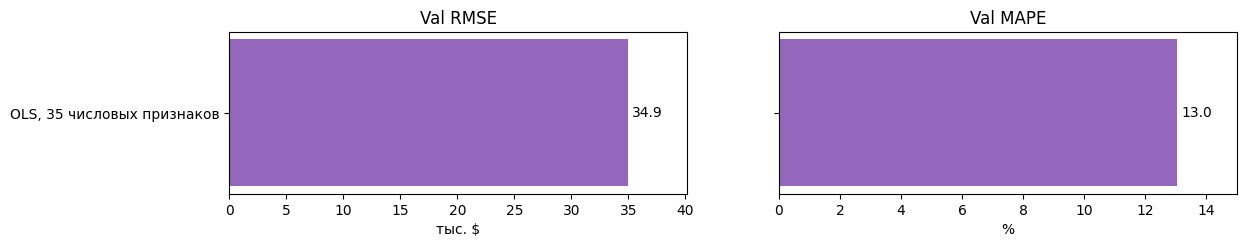

In [149]:
plot_experiments(df_res)

### Мультиколлинеарность

Возможно, не самое хорошее качество решения задачи связано с мультиколлинеарностью — наличием сильно коррелирующих между собой признаков.

Поэтому вычислим коррелограмму (матрица попарных корреляций всех переменных) и проанализируем её.

<Axes: >

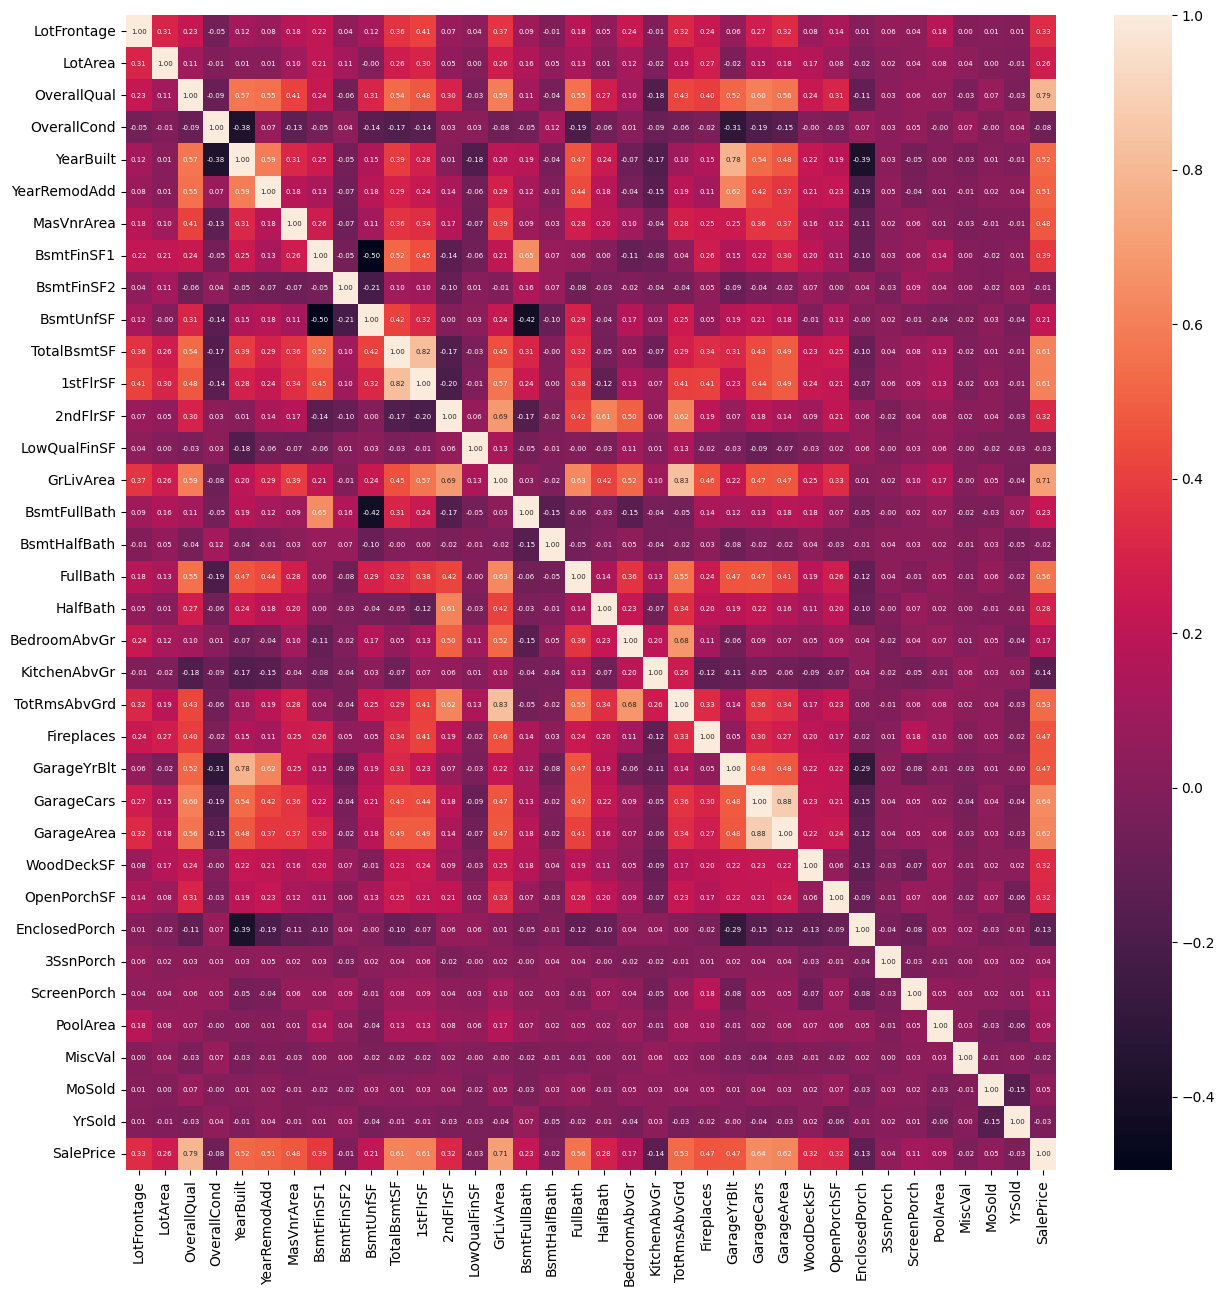

In [150]:
data_numeric.corr()
fig, ax = plt.subplots(figsize=(15, 15))
corr = data_numeric.corr()
sns.heatmap(corr,
            xticklabels=corr.columns.values,
            yticklabels=corr.columns.values,
            annot=True,
            annot_kws={"fontsize":5},
            fmt=".2f"
            )

In [151]:
# Удаляем сильно скоррелированные признаки (оставим один из них)
corr_matrix = X_train.corr().abs()  # Отбираем признаки только по обучающей выборке

# Выбираем все над диагональю, так как матрица симметрическая
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Находим переменные, у которых корреляция по модулю больше 0.5
to_drop = [column for column in upper.columns if any(upper[column] > 0.5) and column != 'SalePrice']

# Удаляем отобранные фичи
data_numeric_ = data_numeric.drop(data_numeric[to_drop], axis=1)


In [152]:
to_drop

['YearBuilt',
 'YearRemodAdd',
 'TotalBsmtSF',
 '1stFlrSF',
 'GrLivArea',
 'BsmtFullBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'TotRmsAbvGrd',
 'GarageYrBlt',
 'GarageCars',
 'GarageArea']

In [153]:
print('До удаления скоррелированных ', len(data_numeric.columns))
print('После удаления скоррелированных ', len(data_numeric_.columns))

До удаления скоррелированных  36
После удаления скоррелированных  23


Для чего удалять скоррелированные между собой признаки?

Обучим модели ещё раз и сравним коэффициенты.

In [154]:
# Для начала разобъём выборку на обучающую и валидационную
from sklearn.model_selection import train_test_split
X_train_, X_val_, y_train, y_val = train_test_split(
        data_numeric_.drop(["SalePrice"], axis=1), data_numeric['SalePrice'],
        test_size=0.25, random_state=42
)

In [155]:
%%time
regr = LinearRegression()

regr.fit(X_train_, y_train)

CPU times: total: 93.8 ms
Wall time: 17 ms


LinearRegression()

In [156]:
print(f"Coef. :{regr.intercept_,}")
print(f"Coef. :{regr.coef_,}")

Coef. :(180717.88992508748,)
Coef. :(array([ 1.01153597e+02,  5.47336908e-01,  2.85759642e+04,  5.94832997e+02,
        2.89130267e+01,  5.23762590e+01,  4.01455833e+01,  3.60556649e+01,
        3.28559881e+01,  1.54982020e+01, -1.04877696e+04, -9.25501293e+03,
        7.39383450e+03,  5.31835472e+01,  1.36898903e+01, -4.42958940e+01,
        8.64411140e+01,  5.23271954e+01, -3.65950836e+01, -1.01411633e+00,
       -7.07940049e+01, -1.24856388e+02]),)


Попробуем найти решение с помощью формул из линейной алгебры.

In [157]:
X, y = X_train_.values, y_train.values
coef_reg = solve_linear_regression(X, y)

print(f"Coef. :{coef_reg}")

Coef. :[ 1.80717890e+05  1.01153597e+02  5.47336908e-01  2.85759642e+04
  5.94832997e+02  2.89130267e+01  5.23762590e+01  4.01455833e+01
  3.60556649e+01  3.28559881e+01  1.54982020e+01 -1.04877696e+04
 -9.25501293e+03  7.39383450e+03  5.31835472e+01  1.36898903e+01
 -4.42958940e+01  8.64411140e+01  5.23271954e+01 -3.65950836e+01
 -1.01411633e+00 -7.07940049e+01 -1.24856388e+02]


In [158]:
comparison_no_corr = compare_coefficients(regr, coef_reg, X_train_.columns)
comparison_no_corr.head(8)

,sklearn,вручную,разница
(свободный член),180717.889925,180717.890015,8.956096e-05
BsmtHalfBath,-10487.769629,-10487.769629,3.870755e-07
YrSold,-124.856388,-124.856388,1.163531e-07
KitchenAbvGr,-9255.012932,-9255.012932,9.670293e-08
Fireplaces,7393.834499,7393.834499,6.431401e-08
OverallCond,594.832997,594.832997,1.510693e-08
OverallQual,28575.964181,28575.964181,8.592906e-09
MoSold,-70.794005,-70.794005,7.725077e-09


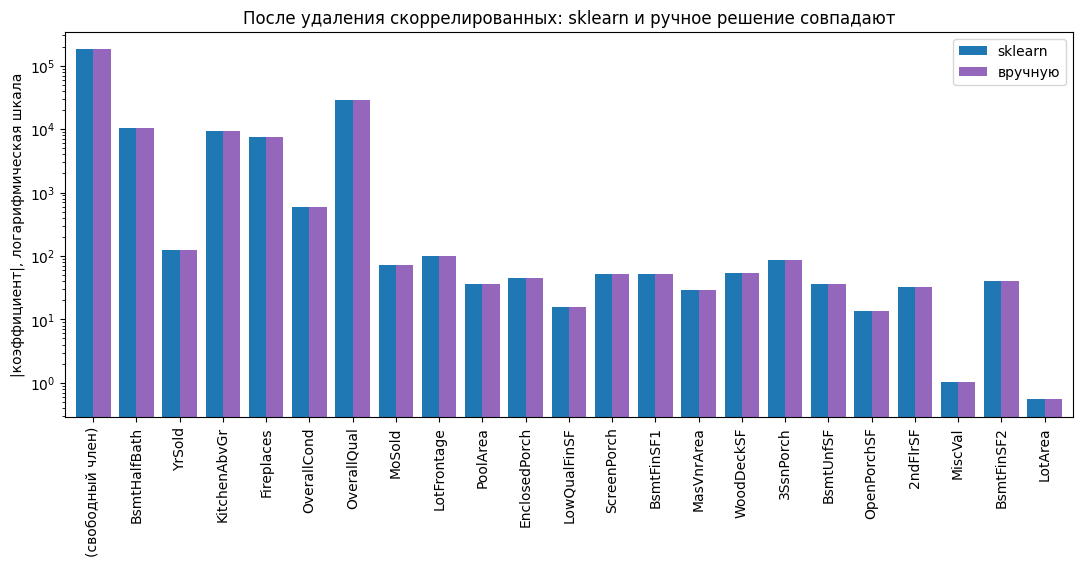

In [159]:
sizes_no_corr = comparison_no_corr[["sklearn", "вручную"]].abs()
ax = sizes_no_corr.plot.bar(logy=True, width=.8, figsize=(13, 5), color=["tab:blue", "tab:purple"])
ax.set(ylabel="|коэффициент|, логарифмическая шкала",
       title="После удаления скоррелированных: sklearn и ручное решение совпадают")
plt.show()

Теперь все совпадает — рукописная модель справляется с задачей.

Посчитаем метрики и добавим в историю экспериментов.

In [160]:
# Получаем предсказания
preds_train = regr.predict(X_train_)
preds_valid = regr.predict(X_val_)

# train / valid RMSE, как раньше
rmse_train = root_mean_squared_error(preds_train, y_train)
rmse_valid = root_mean_squared_error(preds_valid,   y_val)

# Вычислим MAPE
mape_train = mean_absolute_percentage_error(y_train, preds_train)
mape_valid = mean_absolute_percentage_error(y_val, preds_valid)

print(f"Train RMSE: {rmse_train:.1f}")
print(f"Val   RMSE: {rmse_valid:.1f}")
print(f"Train MAPE: {mape_train:.3f}")
print(f"Val   MAPE: {mape_valid:.3f}")


Train RMSE: 39546.7
Val   RMSE: 38337.0
Train MAPE: 0.154
Val   MAPE: 0.151


In [161]:
# Записываем метрики в наш контейнер и выводим таблицу
res['no corr'] = [rmse_train, rmse_valid, mape_train, mape_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmse_train', 'rmse_valid', 'mape_train', 'mape_valid'])
df_res

,rmse_train,rmse_valid,mape_train,mape_valid
base,35170.871526,34927.637697,0.128225,0.130398
no corr,39546.669105,38336.973885,0.153843,0.150866


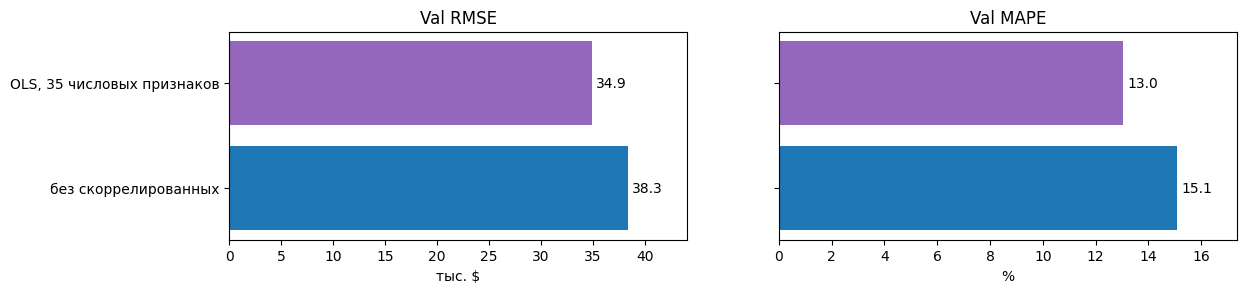

In [162]:
plot_experiments(df_res)

После удаления признаков validation RMSE вырос примерно с 34 928 до 38 337. В этом опыте отбор по порогу корреляции ухудшил качество. При этом результаты ручного и библиотечного расчёта коэффициентов стали ближе.

Далее вернёмся к полному набору числовых признаков и рассмотрим другие способы обучения.

**Вопрос.** Какие ещё существуют способы для борьбы с мультиколлинеарностью?

### Выводы

Аналитическое решение $w = (XᵀX)⁻¹Xᵀy$ даёт «идеальные» коэффициенты в отсутствие шумов и мультиколлинеарности. Но на практике появляются проблемы:

- **Чувствительность к корреляции.** При сильнокоррелированных признаках матрица $XᵀX$ плохо обусловлена или даже вырождается — решение нестабильно или вовсе не вычисляется.

- **Ресурсоёмкость при больших данных.** Обращение ($XᵀX$) требует O($d³$) вычислений и много памяти, что становится узким местом, когда $d$ (число признаков) велико.

В итоге аналитический метод хорош для небольших малошумных задач и даёт ясную формулу, но в реальных сценариях почти всегда требуется:

- предобработка (удаление мультиколлинеарности, масштабирование).

- регуляризация (L2/L1/ElasticNet) или итеративные численные методы (градиентный спуск и его модификации).

## Решение через SGD
Обучим линейную регрессию на тех же данных не через прямое решение, а с помощью метода градиентного
спуска.

Модель `Ridge` уже можно обучить с применением этого метода: есть параметр `solver`, который контролирует процесс.


**Вопрос.** Зачем использовать SGD?

**Вопрос.** Какие могут быть проблемы на больших данных?

### Итеративное обучение: SAG

Здесь используем SAG (Stochastic Average Gradient). Это стохастический метод, который хранит и обновляет оценки градиентов по объектам. Сравним влияние числа итераций и масштаба признаков на результат обучения.

| Метод | Градиент считается по | Шаг | Шум | Память |
|---|---|---|---|---|
| **GD** (обычный) | всем $n$ объектам | дорогой, $O(nd)$ | нет, точное направление | — |
| **SGD** | одному случайному объекту | дешёвый | большой, траектория скачет | — |
| **SAG** | одному случайному объекту, но шаг — среднее по $n$ сохранённым градиентам | дешёвый | почти нет | хранит $n$ градиентов |

In [55]:
# Импортируем Ridge-регрессию
from sklearn.linear_model import Ridge

In [163]:
%%time
# alpha=0 отключает регуляризацию в этом опыте
regr = Ridge(alpha=0, solver='sag', random_state=42, max_iter=1000)
regr.fit(X_train, y_train)
print("Число итераций:", regr.n_iter_)

Число итераций: [1000]
CPU times: total: 281 ms
Wall time: 325 ms


c:\Users\anyho\CU_teach\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning:

The max_iter was reached which means the coef_ did not converge



In [165]:
# Получаем предсказания
preds_train = regr.predict(X_train)
preds_valid = regr.predict(X_val)

# train / valid RMSE, как раньше
rmse_train = root_mean_squared_error(preds_train, y_train)
rmse_valid = root_mean_squared_error(preds_valid,   y_val)

# Вычисляем MAPE
mape_train = mean_absolute_percentage_error(y_train, preds_train)
mape_valid = mean_absolute_percentage_error(y_val, preds_valid)

print(f"Train RMSE: {rmse_train:.1f}")
print(f"Val   RMSE: {rmse_valid:.1f}")
print(f"Train MAPE: {mape_train:.3f}")
print(f"Val   MAPE: {mape_valid:.3f}")


Train RMSE: 45840.1
Val   RMSE: 41687.4
Train MAPE: 0.164
Val   MAPE: 0.157


In [166]:
# В предыдущем эксперименте задано max_iter=1000
res['Ridge_1000_iter'] = [rmse_train, rmse_valid, mape_train, mape_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmse_train', 'rmse_valid', 'mape_train', 'mape_valid'])
df_res

,rmse_train,rmse_valid,mape_train,mape_valid
base,35170.871526,34927.637697,0.128225,0.130398
no corr,39546.669105,38336.973885,0.153843,0.150866
Ridge_1000_iter,45840.092124,41687.355903,0.164385,0.156939


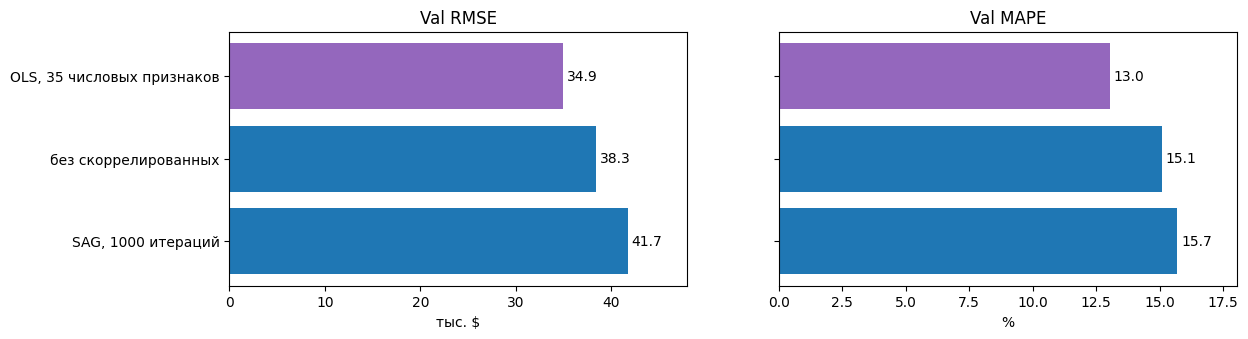

In [167]:
plot_experiments(df_res)

Алгоритм достиг лимита в 1000 итераций, не выполнив условие сходимости. Об этом сообщает `ConvergenceWarning`. Сначала увеличим лимит, затем сравним результат с обучением на масштабированных признаках.

In [169]:
10_000

10000

In [174]:
%%time
regr = Ridge(alpha=0, solver='sag', random_state=42, max_iter=20_000)
regr.fit(X_train, y_train)

CPU times: total: 2.33 s
Wall time: 2.94 s


Ridge(alpha=0, max_iter=20000, random_state=42, solver='sag')

Параметр `max_iter` задаёт максимальное число итераций. Увеличение лимита даёт алгоритму больше времени на поиск решения.

Для SAG в `Ridge` параметр `tol` задаёт порог относительного изменения коэффициентов. Когда изменение достаточно мало, обучение останавливается. Если раньше достигнут `max_iter`, появляется предупреждение о несходимости. Фактическое число итераций хранится в `n_iter_`.

Масштабирование признаков тоже влияет на скорость сходимости. Проверим это в следующем опыте.

In [175]:
y_pred_train = regr.predict(X_train)
y_pred_val   = regr.predict(X_val)

# RMSE
rmse_train = root_mean_squared_error(y_train, y_pred_train)
rmse_valid = root_mean_squared_error(y_val,   y_pred_val)

# MAPE
mape_train = mean_absolute_percentage_error(y_train, y_pred_train)
mape_valid = mean_absolute_percentage_error(y_val,   y_pred_val)

print(f"Train RMSE: {rmse_train:.1f}")
print(f"Val   RMSE: {rmse_valid:.1f}")
print(f"Train MAPE: {mape_train:.3f}")
print(f"Val   MAPE: {mape_valid:.3f}")

Train RMSE: 43722.4
Val   RMSE: 40337.4
Train MAPE: 0.154
Val   MAPE: 0.151


In [176]:
res['Ridge_10000_iter'] = [rmse_train, rmse_valid, mape_train, mape_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmse_train', 'rmse_valid', 'mape_train', 'mape_valid'])
df_res

,rmse_train,rmse_valid,mape_train,mape_valid
base,35170.871526,34927.637697,0.128225,0.130398
no corr,39546.669105,38336.973885,0.153843,0.150866
Ridge_1000_iter,45840.092124,41687.355903,0.164385,0.156939
Ridge_10000_iter,43722.429808,40337.377679,0.153537,0.150625


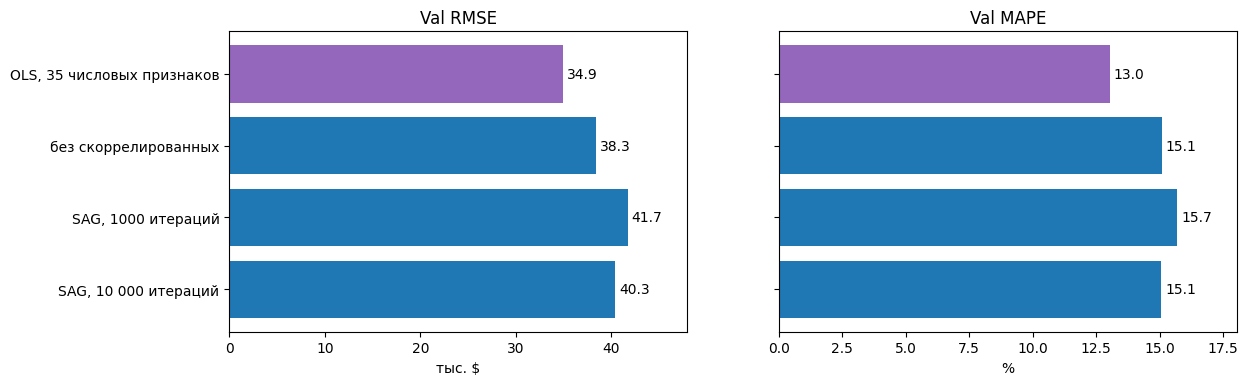

In [177]:
plot_experiments(df_res)

Дополнительные итерации улучшили сходимость: ошибки на обучающей и валидационной выборках уменьшились.

### Нормализация признаков

Зачем производить нормализацию признаков?

Воспользуемся [MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html) из sklearn.

Его формула:
$$X_{norm} = \frac{X - X.min(axis=0)}{X.max(axis=0) - X.min(axis=0)}$$

In [178]:
# Также всё обернём в удобный функционал пайпинга от sklearn, чтобы можно было работать с моделью всё также в формате fit predict, но был встроенный препроцессинг
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

In [179]:
pipe = Pipeline([
    ("scaler", MinMaxScaler()),
    ("regr", Ridge(alpha=0, solver='sag', random_state=42, max_iter=10_000))
])


In [180]:
%%time
pipe.fit(X_train, y_train)

CPU times: total: 15.6 ms
Wall time: 18.5 ms


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('regr',
                 Ridge(alpha=0, max_iter=10000, random_state=42,
                       solver='sag'))])

In [181]:
y_pred_train = pipe.predict(X_train)
y_pred_val   = pipe.predict(X_val)

# RMSE
rmse_train = root_mean_squared_error(y_train, y_pred_train)
rmse_valid = root_mean_squared_error(y_val,   y_pred_val)

# MAPE
mape_train = mean_absolute_percentage_error(y_train, y_pred_train)
mape_valid = mean_absolute_percentage_error(y_val,   y_pred_val)

print(f"Train RMSE: {rmse_train:.1f}")
print(f"Val   RMSE: {rmse_valid:.1f}")
print(f"Train MAPE: {mape_train:.3f}")
print(f"Val   MAPE: {mape_valid:.3f}")

Train RMSE: 35170.9
Val   RMSE: 34927.4
Train MAPE: 0.128
Val   MAPE: 0.130


In [182]:
res['Ridge_10000_iter_norm'] = [rmse_train, rmse_valid, mape_train, mape_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmse_train', 'rmse_valid', 'mape_train', 'mape_valid'])
df_res

,rmse_train,rmse_valid,mape_train,mape_valid
base,35170.871526,34927.637697,0.128225,0.130398
no corr,39546.669105,38336.973885,0.153843,0.150866
Ridge_1000_iter,45840.092124,41687.355903,0.164385,0.156939
Ridge_10000_iter,43722.429808,40337.377679,0.153537,0.150625
Ridge_10000_iter_norm,35170.871719,34927.422288,0.128223,0.130393


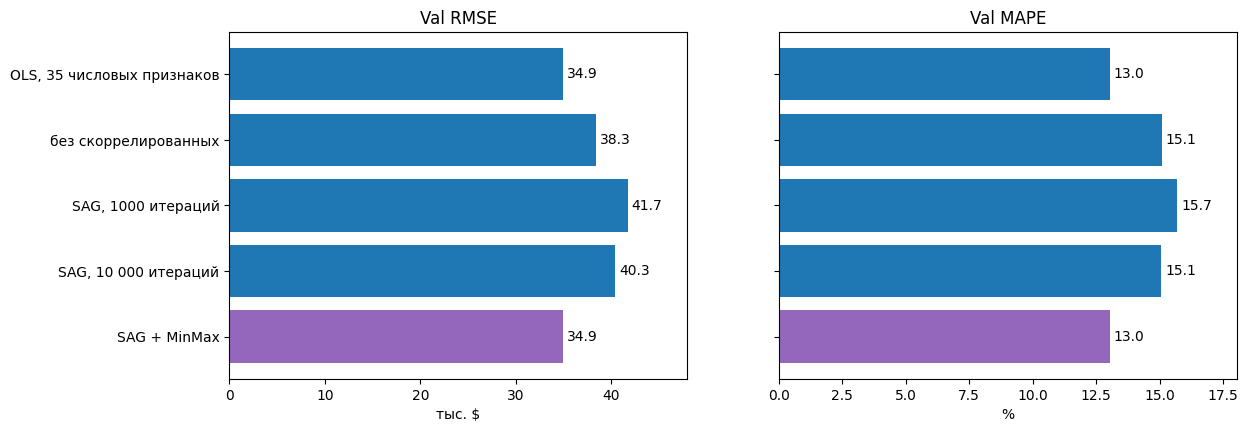

In [183]:
plot_experiments(df_res)

**Вопрос.** Какие ещё варианты нормализации признаков существуют?

### Выводы

* Модель стала сходиться гораздо быстрее.
* Качество при том же максимальном числе итераций тоже улучшилось.

Соберём это в одну картинку: слева то, что алгоритм минимизирует, справа качество на валидации.

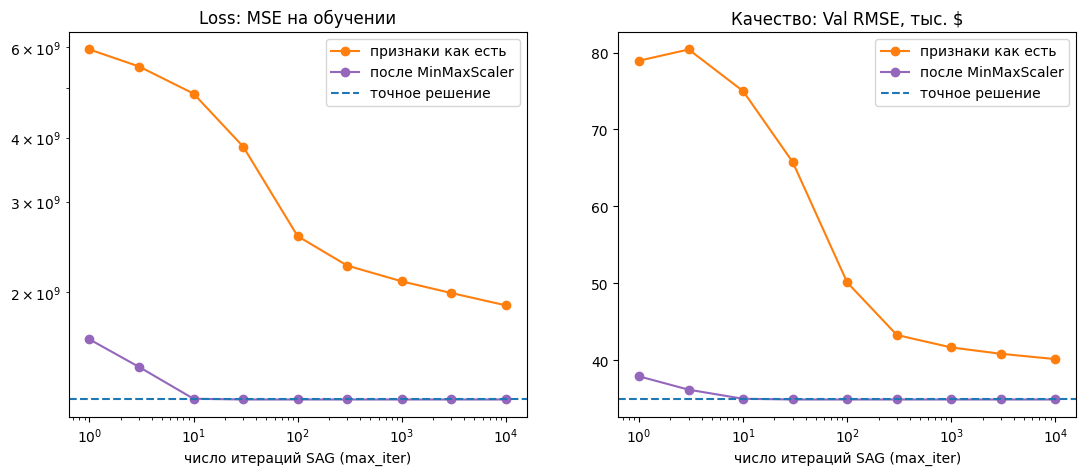

In [184]:
from sklearn.metrics import mean_squared_error
from warnings import catch_warnings, simplefilter

iterations = [1, 3, 10, 30, 100, 300, 1000, 3000, 10_000]
scaler = MinMaxScaler().fit(X_train)


def sag_convergence(X_tr, X_v):
    """Loss на обучении и RMSE на валидации для разного числа итераций SAG."""
    train_loss, val_rmse = [], []

    for n_iter in iterations:
        model = Ridge(alpha=0, solver="sag", random_state=42, max_iter=n_iter, tol=1e-12)
        model.fit(X_tr, y_train)
        train_loss.append(mean_squared_error(y_train, model.predict(X_tr)))
        val_rmse.append(root_mean_squared_error(y_val, model.predict(X_v)) / 1e3)

    return train_loss, val_rmse


with catch_warnings():
    simplefilter("ignore")                 # на малых max_iter ConvergenceWarning ожидаем
    raw = sag_convergence(X_train, X_val)
    scaled = sag_convergence(scaler.transform(X_train), scaler.transform(X_val))

exact = LinearRegression().fit(X_train, y_train)
exact_loss = mean_squared_error(y_train, exact.predict(X_train))
exact_rmse = root_mean_squared_error(y_val, exact.predict(X_val)) / 1e3

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
panels = [(0, "Loss: MSE на обучении", exact_loss, True),
          (1, "Качество: Val RMSE, тыс. $", exact_rmse, False)]

for ax, (index, title, exact_value, log_scale) in zip(axes, panels):
    ax.plot(iterations, raw[index], "o-", color="tab:orange", label="признаки как есть")
    ax.plot(iterations, scaled[index], "o-", color="tab:purple", label="после MinMaxScaler")
    ax.axhline(exact_value, color="tab:blue", ls="--", label="точное решение")
    ax.set(xscale="log", xlabel="число итераций SAG (max_iter)", title=title)
    if log_scale:
        ax.set_yscale("log")
    ax.legend()

plt.show()

Слева видно, что именно минимизирует алгоритм, справа к чему это приводит на валидации. После масштабирования обе кривые выходят на уровень точного решения за 10-30 итераций. Без масштабирования даже 10 000 итераций не хватает: признаки различаются по масштабу на порядки, и оптимизатор идёт по узкому оврагу.

Масштабирование здесь чинит сходимость, а не качество модели: точное решение одно и то же.

## Виды регуляризации

### L2-регуляризация:

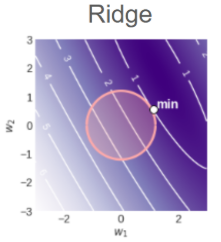

На рисунке выше показано, как выглядит ограничения L2 в пространстве коэффициентов.



$$\|Xw - y\|^2 + \lambda\|w\|^2 \rightarrow \min_w$$

**Вопрос.** Обязательно ли нормализовывать признаки при использовании регуляризации?

Рассмотрим методы на простом примере, сгенерируем данные со скоррелированными признаками и проанализируем, как в этом случае может помочь [регуляризация](https://neerc.ifmo.ru/wiki/index.php?title=%D0%A0%D0%B5%D0%B3%D1%83%D0%BB%D1%8F%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D1%8F).

$y = w_1x_1 + w_2x_2 + w_3x_3 +\epsilon$

In [185]:
# Фиксируем генерацию данных для воспроизводимости эксперимента
np.random.seed(42)

n_features = 3
n_objects = 300
eps = 1e-3

w_true = np.random.normal(size=(n_features, )) # Веса, которые будем использовать при создании линейной зависимости

X = np.random.uniform(-5, 5, (n_objects, n_features))

X[:, -1] = X[:, -2] + np.random.uniform(-eps, eps, X[:, -2].shape) # X_1 = X_0 + noise -> X_1 ~ X_0

Y = X.dot(w_true) + np.random.normal(0, 1, (n_objects))


In [186]:
# Обучим на этих данных модель без регуляризации
model = Ridge(alpha=0)

In [187]:
model.fit(X, Y)

Ridge(alpha=0)

In [188]:
# w1 + w3 ~ 0, это делает модель нестабильной
# Попробуем решить эту проблему через регуляризацию
model.coef_

array([  0.50958876,  93.81229507, -93.25089289])

**Вопрос.** Что не так с коэффициентами?

In [189]:
w_true

array([ 0.49671415, -0.1382643 ,  0.64768854])

In [190]:
from sklearn.metrics import mean_squared_error

# Один проверочный набор для обеих моделей
rng = np.random.default_rng(42)
X_check = rng.uniform(-5, 5, size=(15, n_features))
X_check[:, -1] = (
    X_check[:, -2] + rng.uniform(-eps, eps, size=15)
)
y_check = X_check @ w_true + rng.normal(0, 1, size=15)

mse_no_reg = mean_squared_error(y_check, model.predict(X_check))
print(f"Без регуляризации: MSE = {mse_no_reg:.3f}")

Без регуляризации: MSE = 0.777


Попробуем добавить регуляризацию.

In [77]:
# Обучим модель с ненулевым коэффициентом регуляризации
model_reg = Ridge(alpha=0.1)

In [191]:
model_reg.fit(X, Y)

Ridge(alpha=0.1)

In [192]:
model_reg.coef_

array([0.50965702, 0.33010772, 0.23114221])

In [193]:
w_true

array([ 0.49671415, -0.1382643 ,  0.64768854])

Коэффициенты явно совпадают лучше.

In [194]:
# Сравниваем прогнозы на тех же объектах и ответах
for name, fitted_model in [
    ("Без регуляризации", model),
    ("С регуляризацией", model_reg),
]:
    mse = mean_squared_error(y_check, fitted_model.predict(X_check))
    print(f"{name}: MSE = {mse:.3f}")

Без регуляризации: MSE = 0.777
С регуляризацией: MSE = 0.760


**Вопросы.** Какая модель лучше восстановила коэффициенты? Какая точнее предсказывает на общей проверочной выборке?

Сравни эти результаты отдельно. При сильно скоррелированных признаках разные коэффициенты могут давать близкие прогнозы.

### Lasso и ElasticNet

Следующим шагом добавим подбор параметров и выбор модели через кросс-валидацию.

Модели также будем выбирать линейные. Мы уже работли с Ridge-регрессией, но в лекции и в семинаре выше упоминались модели `Lasso` и `Elastic Net` — рассмотрим их тоже.

В sklearn для многих моделей машинного обучения есть встроенные классы с автоматическим `cross-validation`, одним из них и воспользуемся.

In [89]:
# Импортируем нужные классы
from sklearn.linear_model import ElasticNet, Lasso
from sklearn.model_selection import GridSearchCV

Sklearn выбирает параметры CV с большей метрикой, которая передается в scoring-аргумент. Для задачи регрессии чем меньше RMSE, тем лучше. Поэтому необходимо передавать -RMSE, чтобы соответствовать API sklearn: чем больше будет в таком случае метрика, тем меньше будет её значение ([документация](https://scikit-learn.org/stable/modules/model_evaluation.html)).

**Вопрос.** Чем отличаются Ridge, Lasso и ElasticNet?

Запиши функции потерь. Затем нарисуй линии уровня штрафов в пространстве двух коэффициентов $w_1$ и $w_2$.

По осям отложены коэффициенты модели. Каждая точка задаёт пару коэффициентов. На одной линии находятся пары с одинаковым штрафом. Например, линия $|w_1| + |w_2| = 1$ состоит из всех пар, у которых сумма модулей равна 1.

Объясни, при какой регуляризации коэффициенты могут стать равными нулю и как это связано с формой линий уровня штрафа.

Проверим это на наших данных из эксперимента выше. Возьмём плоскость двух последних весов $w_2$ и $w_3$ (это и есть пара почти одинаковых признаков), а первый вес и свободный член закрепим на значениях обычной регрессии.

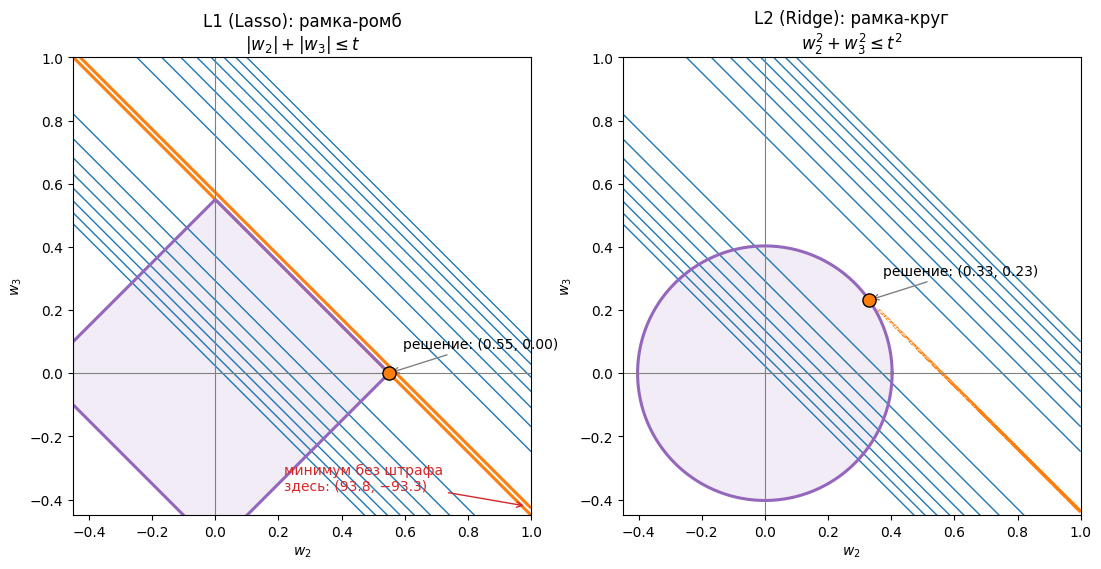

In [195]:
ols = LinearRegression().fit(X, Y)
ridge_model = Ridge(alpha=0.1).fit(X, Y)
lasso_model = Lasso(alpha=0.1).fit(X, Y)


def mse_on_grid(w2, w3):
    """MSE на наших данных для пары весов. Первый вес и свободный член закреплены."""
    prediction = (ols.intercept_ + ols.coef_[0] * X[:, 0]
                  + w2[..., None] * X[:, 1] + w3[..., None] * X[:, 2])
    return ((prediction - Y) ** 2).mean(axis=-1)


grid = np.linspace(-0.45, 1.0, 400)
w2_grid, w3_grid = np.meshgrid(grid, grid)
loss_surface = mse_on_grid(w2_grid, w3_grid)

# Рамки строим по длине реальных решений: ромб по L1-норме Lasso, круг по L2-норме Ridge
angle = np.linspace(0, 2 * np.pi, 400)
unit_circle = np.c_[np.cos(angle), np.sin(angle)]
diamond = np.abs(lasso_model.coef_[1:]).sum() * unit_circle / np.abs(unit_circle).sum(axis=1, keepdims=True)
circle = np.linalg.norm(ridge_model.coef_[1:]) * unit_circle

panels = [("L1 (Lasso): рамка-ромб\n$|w_2| + |w_3| \\leq t$", diamond, lasso_model),
          ("L2 (Ridge): рамка-круг\n$w_2^2 + w_3^2 \\leq t^2$", circle, ridge_model)]

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))

for ax, (title, boundary, model) in zip(axes, panels):
    solution = model.coef_[1:]

    ax.contour(w2_grid, w3_grid, loss_surface, colors="tab:blue", linewidths=1.0,
               levels=np.linspace(loss_surface.min(), loss_surface.min() + 2.5, 9))
    ax.contour(w2_grid, w3_grid, loss_surface, colors="tab:orange", linewidths=2.2,
               levels=[mse_on_grid(*solution[:, None])[0]])
    ax.fill(*boundary.T, color="tab:purple", alpha=.12)
    ax.plot(*np.vstack([boundary, boundary[:1]]).T, color="tab:purple", lw=2.2)
    ax.scatter(*solution, s=90, color="tab:orange", edgecolor="black", zorder=5)

    ax.annotate(f"решение: ({solution[0]:.2f}, {solution[1]:.2f})", solution,
                xytext=(10, 18), textcoords="offset points",
                arrowprops=dict(arrowstyle="->", color="gray"))
    ax.axhline(0, color="gray", lw=.8)
    ax.axvline(0, color="gray", lw=.8)
    ax.set(xlabel="$w_2$", ylabel="$w_3$", title=title, aspect="equal",
           xlim=(-0.45, 1.0), ylim=(-0.45, 1.0))

axes[0].annotate("минимум без штрафа\nздесь: (93.8, −93.3)", xy=(.99, .02), xytext=(.46, .055),
                 xycoords="axes fraction", textcoords="axes fraction", color="tab:red",
                 arrowprops=dict(arrowstyle="->", color="tab:red"))
plt.show()

**Как читать.** Синие линии это линии уровня MSE на наших данных, фиолетовая фигура это допустимая область для весов, оранжевая линия уровня та, что первой касается рамки, и точка на ней это решение.

* Линии уровня почти параллельны. Это прямое следствие того, что $x_2$ и $x_3$ почти совпадают: модели важна только сумма $w_2 + w_3$, а как её поделить между двумя признаками, данные не говорят. Поэтому минимум без штрафа уезжает далеко по этому оврагу, в точку $(93{,}8,\ -93{,}3)$.
* **Lasso** касается ромба **ровно в углу**: решение $(0{,}55,\ 0)$, третий признак выброшен.
* **Ridge** касается круга в обычной точке: решение $(0{,}33,\ 0{,}23)$, оба веса ненулевые и близки друг к другу.

Рамки нарисованы не произвольно: их размер взят из длины реальных решений `Lasso(alpha=0.1)` и `Ridge(alpha=0.1)`. Чем больше alpha, тем меньше рамка.

Картинка выше это сильное приближение: обе рамки меньше единицы, а настоящий минимум лежит в точке $(94,\ -93)$. Отойдём подальше и посмотрим на линии уровня целиком, уже без рамок.

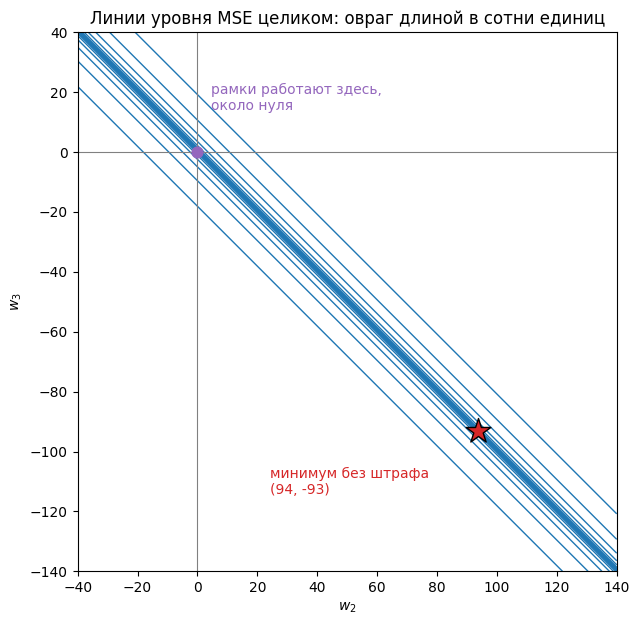

In [196]:
zoom_w2 = np.linspace(-40, 140, 500)
zoom_w3 = np.linspace(-140, 40, 500)
zoom_grid = np.meshgrid(zoom_w2, zoom_w3)
zoom_loss = mse_on_grid(*zoom_grid)

fig, ax = plt.subplots(figsize=(7.5, 7))

ax.contour(*zoom_grid, zoom_loss, colors="tab:blue", linewidths=1.0,
           levels=zoom_loss.min() + np.geomspace(0.05, 3000, 10))
ax.scatter(*ols.coef_[1:], marker="*", s=350, color="tab:red", edgecolor="black", zorder=5)
ax.annotate(f"минимум без штрафа\n({ols.coef_[1]:.0f}, {ols.coef_[2]:.0f})", ols.coef_[1:],
            xytext=(-150, -45), textcoords="offset points", color="tab:red")
ax.scatter(0, 0, s=60, color="tab:purple", zorder=5)
ax.annotate("рамки работают здесь,\nоколо нуля", (0, 0),
            xytext=(10, 30), textcoords="offset points", color="tab:purple")
ax.axhline(0, color="gray", lw=.8)
ax.axvline(0, color="gray", lw=.8)
ax.set(xlabel="$w_2$", ylabel="$w_3$", aspect="equal",
       title="Линии уровня MSE целиком: овраг длиной в сотни единиц")
plt.show()

**Как читать.** Это те же линии уровня, что и на предыдущей картинке, но в масштабе в сто раз крупнее. Эллипсы настолько вытянуты, что похожи на полосы: вдоль оврага длина порядка сотен, поперёк меньше единицы. Звезда это минимум без штрафа, фиолетовая точка это начало координат, где помещаются обе рамки.

Отсюда видно, зачем нужна регуляризация: без неё решение уезжает по дну оврага в точку с огромными весами, хотя качество вдоль всего оврага почти одинаковое.

**Почему на предыдущей картинке линии на разном расстоянии.** MSE квадратична, а значит при равных шагах по значению расстояние между соседними линиями убывает: чтобы ошибка выросла вдвое, отойти надо не вдвое, а примерно в $\sqrt{2}$ раз. Плюс мы смотрели на кусок далеко от минимума, где эллипсы уже почти прямые.

In [197]:
from sklearn.impute import SimpleImputer

# Сохраняем разбиение. Для CV берём признаки с исходными пропусками
X_train = data_numeric_raw.drop(columns="SalePrice").loc[y_train.index]
X_val = data_numeric_raw.drop(columns="SalePrice").loc[y_val.index]

# Все обучаемые преобразования выполняются заново на каждом train-фолде
def make_numeric_pipeline(regressor):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", MinMaxScaler()),
        ("regr", regressor)
    ])

# Ridge
model_ridge = GridSearchCV(
    make_numeric_pipeline(Ridge(max_iter=10000)),
    param_grid={"regr__alpha": np.logspace(-3, 3, 20)},
    cv=5, scoring="neg_root_mean_squared_error"
)

# Lasso
model_lasso = GridSearchCV(
    make_numeric_pipeline(Lasso(max_iter=10000)),
    param_grid={"regr__alpha": np.logspace(-3, 3, 20)},
    cv=5, scoring="neg_root_mean_squared_error"
)

# Elastic Net
model_elastic = GridSearchCV(
    make_numeric_pipeline(ElasticNet(max_iter=10000)),
    param_grid={"regr__alpha": np.logspace(-3, 3, 20),
                "regr__l1_ratio": np.linspace(0.05, 1.0, 20)},
    cv=5, scoring="neg_root_mean_squared_error"
)

model_ridge.fit(X_train, y_train)
model_lasso.fit(X_train, y_train)
model_elastic.fit(X_train, y_train)

# Лучшие α
print("Ridge best params: ", model_ridge.best_params_)
print("Lasso best params:", model_lasso.best_params_)
print("ElasticNet best params:", model_elastic.best_params_)

# RMSE на валидации
rmse_ridge   = root_mean_squared_error(y_val, model_ridge.predict(X_val))
rmse_lasso   = root_mean_squared_error(y_val, model_lasso.predict(X_val))
rmse_enet    = root_mean_squared_error(y_val, model_elastic.predict(X_val))

print(f"Ridge RMSE:   {rmse_ridge:.3f}")
print(f"Lasso RMSE:   {rmse_lasso:.3f}")
print(f"ElasticNet RMSE: {rmse_enet:.3f}")

# best_score_ уже возвращает NEGATIVE RMSE, поэтому:
print(f"Ridge CV RMSE:   {-model_ridge.best_score_:.3f}")
print(f"Lasso CV RMSE:   {-model_lasso.best_score_:.3f}")
print(f"ElasticNet CV RMSE: {-model_elastic.best_score_:.3f}")



c:\Users\anyho\CU_teach\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.552e+08, tolerance: 5.473e+08

c:\Users\anyho\CU_teach\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.553e+08, tolerance: 5.473e+08

c:\Users\anyho\CU_teach\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.555e+08, tolerance: 5.473e+08

c:\Users\anyho\CU_teach\.venv\Lib\site-packages\skle

Ridge best params:  {'regr__alpha': 2.976351441631316}
Lasso best params: {'regr__alpha': 112.88378916846884}
ElasticNet best params: {'regr__alpha': 0.008858667904100823, 'regr__l1_ratio': 0.5499999999999999}
Ridge RMSE:   35985.678
Lasso RMSE:   35776.938
ElasticNet RMSE: 36471.040
Ridge CV RMSE:   39959.250
Lasso CV RMSE:   40313.959
ElasticNet CV RMSE: 39952.132


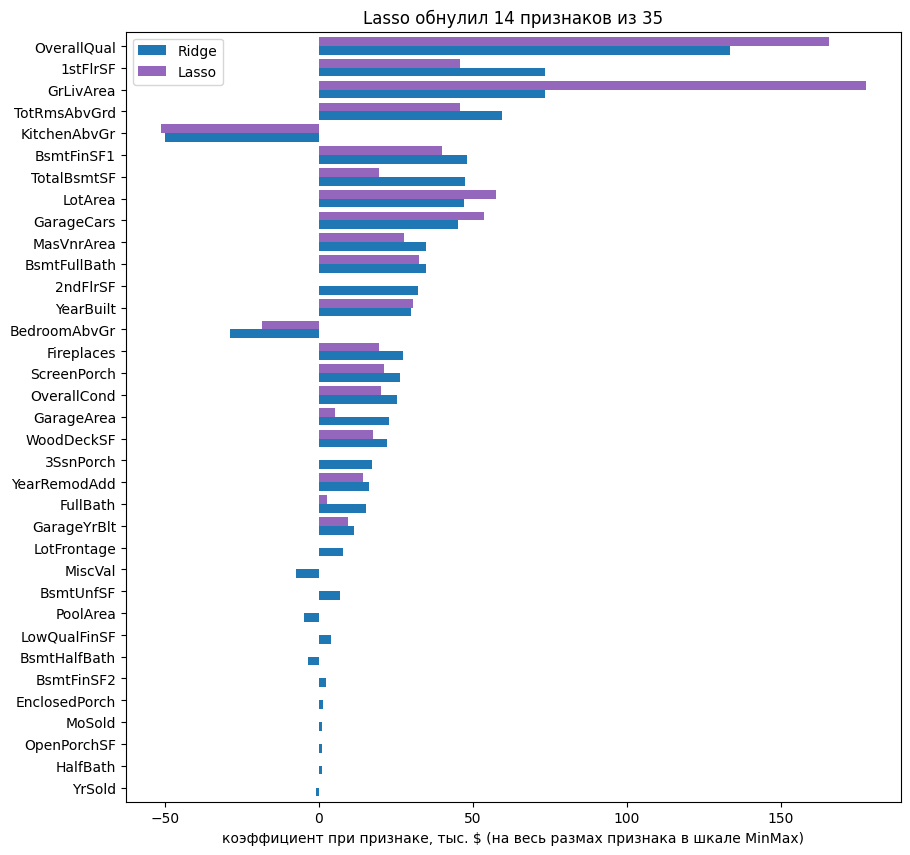

In [198]:
coefficients = pd.DataFrame({
    "Ridge": model_ridge.best_estimator_[-1].coef_,
    "Lasso": model_lasso.best_estimator_[-1].coef_,
}, index=X_train.columns) / 1e3

order = coefficients["Ridge"].abs().sort_values().index
zeroed = (coefficients["Lasso"] == 0).sum()

ax = coefficients.loc[order].plot.barh(figsize=(10, 10), width=.8, color=["tab:blue", "tab:purple"])
ax.set(xlabel="коэффициент при признаке, тыс. $ (на весь размах признака в шкале MinMax)",
       title=f"Lasso обнулил {zeroed} признаков из {len(coefficients)}")
plt.show()

In [199]:
to_drop

['YearBuilt',
 'YearRemodAdd',
 'TotalBsmtSF',
 '1stFlrSF',
 'GrLivArea',
 'BsmtFullBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'TotRmsAbvGrd',
 'GarageYrBlt',
 'GarageCars',
 'GarageArea']

У обнулённых признаков фиолетового столбика нет вовсе. Lasso оставил крупные признаки (`OverallQual`, `GrLivArea`, `TotalBsmtSF`) и выбросил мелкие вроде `MoSold`, `YrSold`, `PoolArea`. Ridge никого не обнулил, он только сжал коэффициенты.

Цена отбора: val RMSE у Lasso 35 777 против 35 986 у Ridge, то есть разницы практически нет, но признаков в модели меньше.

Для следующих опытов возьмём лучший вариант Ridge, выбранный по кросс-валидации. Продолжим сравнивать преобразования в рамках этого семейства моделей.

In [200]:
# GridSearchCV уже обучил лучший пайплайн на всей обучающей выборке
pipe = model_ridge.best_estimator_

# RMSE вручную
rmse_train = root_mean_squared_error(y_train, pipe.predict(X_train))
rmse_valid = root_mean_squared_error(y_val,   pipe.predict(X_val))

mape_train = mean_absolute_percentage_error(y_train, pipe.predict(X_train))
mape_valid = mean_absolute_percentage_error(y_val,   pipe.predict(X_val))

print(f"Train RMSE: {rmse_train:.1f}")
print(f"Val   RMSE: {rmse_valid:.1f}")
print('----------------------------------')
print(f"Train MAPE: {mape_train:.3f}")
print(f"Val   MAPE: {mape_valid:.3f}")



Train RMSE: 35644.0
Val   RMSE: 35985.7
----------------------------------
Train MAPE: 0.129
Val   MAPE: 0.132


In [201]:
res['Ridge_best_model'] = [rmse_train, rmse_valid, mape_train, mape_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmse_train', 'rmse_valid', 'mape_train', 'mape_valid'])
df_res


,rmse_train,rmse_valid,mape_train,mape_valid
base,35170.871526,34927.637697,0.128225,0.130398
no corr,39546.669105,38336.973885,0.153843,0.150866
Ridge_1000_iter,45840.092124,41687.355903,0.164385,0.156939
Ridge_10000_iter,43722.429808,40337.377679,0.153537,0.150625
Ridge_10000_iter_norm,35170.871719,34927.422288,0.128223,0.130393
Ridge_best_model,35643.984173,35985.678025,0.128558,0.131820


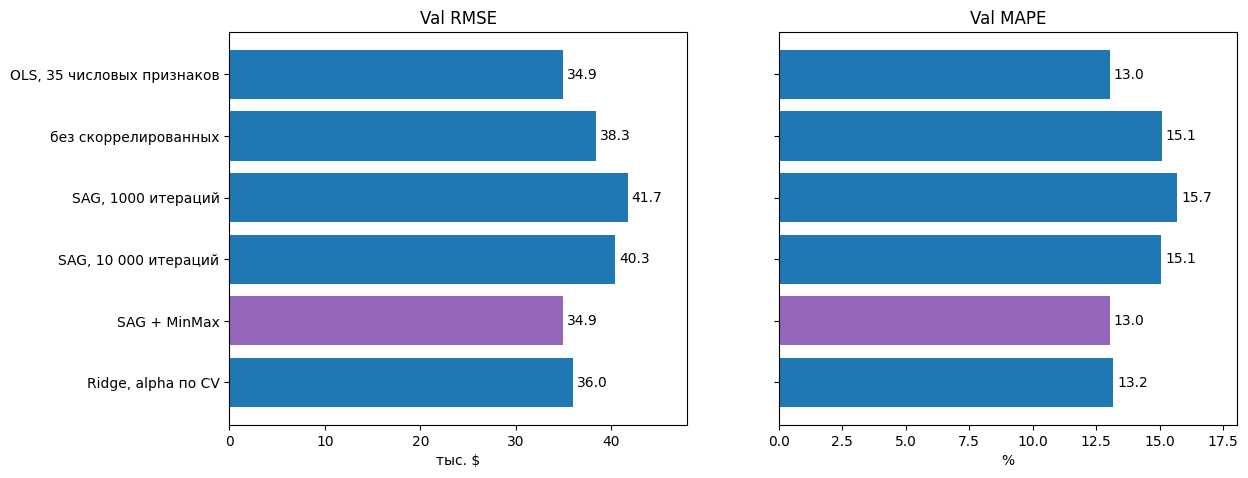

In [95]:
plot_experiments(df_res)

 В `sklearn` в качестве скоринговой функции можно подавать:
1) Саму скоринговую функцию из sklearn.
    - Через строковое описание функции из sklearn ([подробнее](https://scikit-learn.org/stable/modules/model_evaluation.html)).
2) Сделать функцию самостоятельно [через `make_scorer`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.make_scorer.html#sklearn.metrics.make_scorer).


>**Важно.** В `skelarn` действует соглашение, что скоринговую функцию нужно максимизировать, поэтому для представлений через строковое описание ты часто будешь встречать названия функций с приставкой «neg».

## Преобразование целевой переменной

Попробуем предсказывать `log(1 + цена)`. Для больших положительных цен разность логарифмов близка к логарифму отношения цен. Поэтому при таком обучении одинаковые относительные ошибки для дешёвых и дорогих объектов становятся более сопоставимыми.

Проверим, как преобразование повлияет на качество. Вернём прогнозы к исходной шкале цен и посчитаем RMSE и MAPE.

In [96]:
# Визуализируем целевую переменную
px.histogram(
    y_train,
    x="SalePrice"
)

Такое распределение похоже на [лог-нормальное распределение](https://ru.wikipedia.org/wiki/%D0%9B%D0%BE%D0%B3%D0%BD%D0%BE%D1%80%D0%BC%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B5_%D1%80%D0%B0%D1%81%D0%BF%D1%80%D0%B5%D0%B4%D0%B5%D0%BB%D0%B5%D0%BD%D0%B8%D0%B5).

Когда прологарифмируем распределение, оно станет приближенным к нормальному.

In [97]:
np.min(y_train), np.min(y_val)  # Важно следить за неотрицательностью таргета. Здесь с этим всё хорошо

(34900, 35311)

In [202]:
# Прологарифмируем и посмотрим, как теперь выглядит распределение целевой переменной
px.histogram(
    np.log1p(y_train), # np.log(y_train + 1) для большей численной устойчивости
    x="SalePrice"
)

Обучим регрессию на новом таргете, при подсчёте качества вернём таргет обратно.

Единственная сложность — как поступать с CV (кросс-валидация, англ. cross-validation). Для корректного сравнения нужно, чтобы и качество внутри CV считалось на нетрансформированном таргете. Это позволит правильно сравнивать метрики с предыдущим вариантом.

Есть два способа, как с этим работать:
1. Реализовать собственную функцию для оценки качества модели через `make_scorer`.
2. Воспользоваться `TransformedTargetRegressor`, чтобы преобразовавать ответы модели к нужным во время вызова `predict`.

Второй вариант в нашем случае предпочтительнее, так как мы хотим удобно пользоваться методом `predict`. Метод `make_scorer` больше используют для реализации метрик, которых нет в sklearn.

In [203]:
# Если нужно воспользоваться make_scorer, то код будет выглядеть так:
from sklearn.metrics import make_scorer

def neg_exp_rmse(y_true, y_pred):
    res = -root_mean_squared_error(np.expm1(y_true), np.expm1(y_pred))
    return res

Добавим внутрь кросс-валидации трансформацию целевой переменной. Для этого в TransformedTargetRegressor зададим параметры:
1. `regressor` — основная модель, которую мы используем.
2. `func` — прямое преобразование целевой переменной (в нашем случае это логарифмирование).
3. `inverse_func` — обратное преобразование целевой переменной (экспонента).

In [204]:
# Применим TransformedTargetRegressor
from sklearn.compose import TransformedTargetRegressor

In [205]:
# Преобразование таргета и предобработка признаков находятся внутри CV
# Путь regressor__regr__alpha: TransformedTargetRegressor -> Pipeline -> Ridge/Lasso/ElasticNet
model_ridge = GridSearchCV(
    TransformedTargetRegressor(
        regressor=make_numeric_pipeline(Ridge(max_iter=10000)),
        func=np.log1p, inverse_func=np.expm1
    ),
    param_grid={"regressor__regr__alpha": np.logspace(-3, 3, 20)},
    cv=5, scoring="neg_root_mean_squared_error"
)

model_lasso = GridSearchCV(
    TransformedTargetRegressor(
        regressor=make_numeric_pipeline(Lasso(max_iter=10000)),
        func=np.log1p, inverse_func=np.expm1
    ),
    param_grid={"regressor__regr__alpha": np.logspace(-3, 3, 20)},
    cv=5, scoring="neg_root_mean_squared_error"
)

model_elastic = GridSearchCV(
    TransformedTargetRegressor(
        regressor=make_numeric_pipeline(ElasticNet(max_iter=10000)),
        func=np.log1p, inverse_func=np.expm1
    ),
    param_grid={"regressor__regr__alpha": np.logspace(-3, 3, 20),
                "regressor__regr__l1_ratio": np.linspace(0.05, 1.0, 20)},
    cv=5, scoring="neg_root_mean_squared_error"
)

# Обучаем
model_ridge.fit(X_train, y_train)
model_lasso.fit(X_train, y_train)
model_elastic.fit(X_train, y_train)

print("Ridge alpha: ", model_ridge.best_params_, "\nLASSO alpha: ", model_lasso.best_params_, "\nElastic Net", model_elastic.best_params_)
print("Ridge: ", root_mean_squared_error(model_ridge.predict(X_val), y_val))
print("LASSO: ", root_mean_squared_error(model_lasso.predict(X_val), y_val))
print("Elastic: ", root_mean_squared_error(model_elastic.predict(X_val), y_val))

print("Ridge best score: ", -model_ridge.best_score_)
print("LASSO best score: ", -model_lasso.best_score_)
print("Elastic Net best score: ", -model_elastic.best_score_)



Ridge alpha:  {'regressor__regr__alpha': 54.555947811685144} 
LASSO alpha:  {'regressor__regr__alpha': 0.008858667904100823} 
Elastic Net {'regressor__regr__alpha': 0.008858667904100823, 'regressor__regr__l1_ratio': 1.0}
Ridge:  44099.0147200735
LASSO:  45244.60118547447
Elastic:  45244.60118547447
Ridge best score:  49092.82935098718
LASSO best score:  48634.048872606574
Elastic Net best score:  48634.048872606574


In [206]:
# Лучший estimator уже включает предобработку и преобразование таргета
pipe = model_ridge.best_estimator_

mse_train = root_mean_squared_error(pipe.predict(X_train), y_train)
mse_valid = root_mean_squared_error(pipe.predict(X_val), y_val)

mape_train = mean_absolute_percentage_error(y_train, pipe.predict(X_train))
mape_valid = mean_absolute_percentage_error(y_val, pipe.predict(X_val))
print(f"Train RMSE: {mse_train:.1f}")
print(f"Val RMSE: {mse_valid:.1f}")
print('----------------------------------')
print(f"Train MAPE: {mape_train:.3f}")
print(f"Val MAPE: {mape_valid:.3f}")



Train RMSE: 42985.1
Val RMSE: 44099.0
----------------------------------
Train MAPE: 0.138
Val MAPE: 0.145


In [207]:
res['Ridge_best_model_transform_target'] = [mse_train, mse_valid, mape_train, mape_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmse_train', 'rmse_valid', 'mape_train', 'mape_valid'])
df_res


,rmse_train,rmse_valid,mape_train,mape_valid
base,35170.871526,34927.637697,0.128225,0.130398
no corr,39546.669105,38336.973885,0.153843,0.150866
Ridge_1000_iter,45840.092124,41687.355903,0.164385,0.156939
Ridge_10000_iter,43722.429808,40337.377679,0.153537,0.150625
Ridge_10000_iter_norm,35170.871719,34927.422288,0.128223,0.130393
Ridge_best_model,35643.984173,35985.678025,0.128558,0.131820
Ridge_best_model_transform_target,42985.089177,44099.014720,0.138209,0.145048


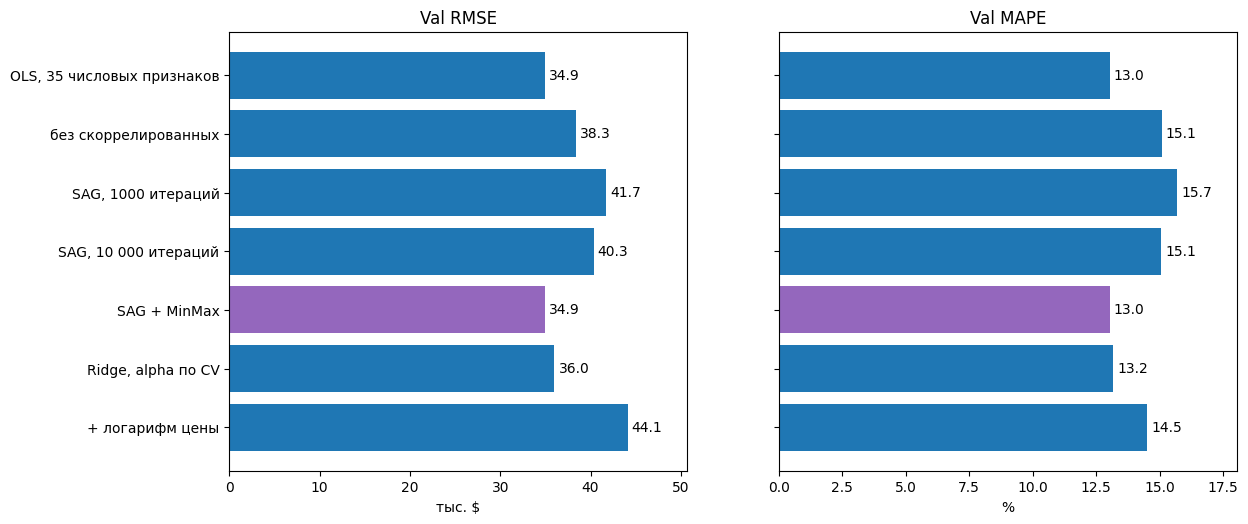

In [208]:
plot_experiments(df_res)

**Вопрос.** Что произошло с RMSE и MAPE после логарифмирования? Какой вариант ты выберешь по этому сравнению?

>Дополнительные материалы по этой теме:
>* [QuantileTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.QuantileTransformer.html)
>* [TransformedTargetRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.compose.TransformedTargetRegressor.html)
>* np.log1p, np.expm1, [пример](https://scikit-learn.org/stable/auto_examples/compose/plot_transformed_target.html#sphx-glr-auto-examples-compose-plot-transformed-target-py)
>* [Как правильно применять трансформацию вместе с CV](https://datasciencewithchris.com/transform-the-target-variable/)

## Обработка категориальных признаков

Предобработка признаков (англ. feature preprocessing) — обязательный этап при работе с линейными моделями. Линейная регрессия напрямую оперирует числами и чувствительна к шкалам и типам признаков.

Способы обработки категориальных признаков (англ. categorical features):

- One-hot encoding (`OneHotEncoder`) — бинарные колонки для каждой категории. При необходимости можно использовать `drop='first'`, чтобы избежать линейной зависимости.
- Ordinal encoding (`OrdinalEncoder`) — только если категории имеют естественный порядок.
- Mean Target Encoding — для каждой категории вычисляется среднее значение целевой переменной.

Используем Mean Target Encoding. **Идея состоит в том, чтобы заменить категорию средним значением таргета для этой категории**.

Упрощённый пример без сглаживания: если в обучающих данных у домов в районе А цены 100 и 140, этому району соответствует число 120. В `TargetEncoder` применяется сглаживание, поэтому результат может отличаться от простого среднего.

Если кодировать обучающий объект с учётом его собственного ответа, часть ответа попадёт в признак. Ниже разберём эту проблему и исправим порядок обучения.

In [209]:
from sklearn.compose import ColumnTransformer  # Пригодится для отдельной обработки вещественных фичей и категориальных
from sklearn.preprocessing import TargetEncoder # Популярный метод

In [211]:
# Соберём наш датасет снова вместе

X = pd.concat([data_numeric_raw.drop(columns="SalePrice"), data_object], axis=1)
y = data.SalePrice

# Сохраняем датасет без категорий, он ещё пригодится
X_train_, y_train_ = X_train.copy(), y_train.copy()

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=42)



#### Задание 2

До этого в работе модели использовались только вещественные переменные. Теперь нужно раздвоить пайплайн, сделать отдельную обработку для вещественных переменных и отдельную для категориальных.

In [212]:
# Вещественные + категориальные
column_transformer = ColumnTransformer([
    ("num_preprocess", Pipeline([("imputer", SimpleImputer(strategy="mean")),
                                 ("scaler", MinMaxScaler())]),
     data_numeric_raw.columns.drop("SalePrice")),
    ("categorial_preprocess", TargetEncoder(target_type="continuous", cv=5, smooth=0.2, random_state=42), data_object.columns)
])

model_ridge = Pipeline(
    [
        ("dataset_numerization", column_transformer),
        ("regr", GridSearchCV(
                    TransformedTargetRegressor(
                        regressor=Ridge(),
                        func=np.log1p,
                        inverse_func=np.expm1
                    ),
                    param_grid={"regressor__alpha": np.logspace(-3, 3, 20)},
                    cv=5,
                    scoring="neg_root_mean_squared_error"
                )
        )
    ],
    verbose=True
)

model_ridge.fit(X_train, y_train)


print("Ridge alpha: ", model_ridge.named_steps["regr"].best_params_)
print("Ridge rmse: ", root_mean_squared_error(model_ridge.predict(X_val), y_val))
print("Ridge best score: ", -model_ridge.named_steps["regr"].best_score_)


[Pipeline]  (step 1 of 2) Processing dataset_numerization, total=   0.0s


c:\Users\anyho\CU_teach\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:215: LinAlgWarning:

Ill-conditioned matrix (rcond=3.9086e-17): result may not be accurate.

c:\Users\anyho\CU_teach\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:215: LinAlgWarning:

Ill-conditioned matrix (rcond=3.76634e-17): result may not be accurate.

c:\Users\anyho\CU_teach\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:215: LinAlgWarning:

Ill-conditioned matrix (rcond=3.85758e-17): result may not be accurate.

c:\Users\anyho\CU_teach\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:215: LinAlgWarning:

Ill-conditioned matrix (rcond=3.82359e-17): result may not be accurate.

c:\Users\anyho\CU_teach\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:215: LinAlgWarning:

Ill-conditioned matrix (rcond=3.76418e-17): result may not be accurate.

c:\Users\anyho\CU_teach\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:215: LinAlgWarning:

Ill-conditioned matrix (rcond=8.0804

[Pipeline] .............. (step 2 of 2) Processing regr, total=   0.6s
Ridge alpha:  {'regressor__alpha': 26.366508987303554}
Ridge rmse:  28695.69797620067
Ridge best score:  36714.94997822134


**Вопрос:** Верно ли мы написали этот цикл обучения? Есть где-то проблемы?

## Корректная обработка признаков без утечек данных

Здесь используются два разбиения с разными задачами.

1. `GridSearchCV` делит данные для выбора силы регуляризации. На каждой итерации весь пайплайн обучается на обучающей части и проверяется на отложенной.
2. Внутри обучающей части `TargetEncoder` делает своё отдельное разбиение. **Для каждой строки код категории рассчитывается по другим фолдам.** Собственный ответ строки не участвует в расчёте её признаков.

Для отложенной части `GridSearchCV` кодировщик использует статистики только обучающей части. Заполнение пропусков и масштабирование также обучаются внутри пайплайна.

В этом примере `TransformedTargetRegressor` передаёт пайплайну логарифмированный таргет. Поэтому кодировщик считает средние значения `log(1 + цена)`. Для оценки качества прогнозы возвращаются к исходной шкале цен.

<pre>
column_transformer:
    TargetEncoder.fit_transform(ВЕСЬ X_train, ВЕСЬ y_train)   ← считает средние по категориям
                                                                  ДО того, как узнал про фолды
    ↓ (готовые числа)
Pipeline:
    GridSearchCV(cv=5):
        TransformedTargetRegressor(Ridge)
            ↑ делит на train/val УЖЕ ЗАКОДИРОВАННЫЕ данные
</pre>

<pre>
GridSearchCV(cv=5):                                ← сначала делит X_train на train/val
    TransformedTargetRegressor:
        regressor = model_eval = Pipeline:
            1. column_transformer (TargetEncoder)  ← .fit() видит ТОЛЬКО train-часть фолда
            2. imputer
            3. scaler
            4. Ridge
</pre>

In [213]:
# Для mean target encoding без утечки целевой переменной
column_transformer = ColumnTransformer([
    ("categorial_preprocess",
     TargetEncoder(target_type="continuous", cv=5, smooth=0.2, random_state=42), data_object.columns)
], remainder="passthrough")

# После преобразования колонок нормализуем и обучаем модель
model_eval = Pipeline([
    ("data_transformer", column_transformer),
    ("imputer", SimpleImputer(strategy="mean")),
    ("num_preprocess", MinMaxScaler()),
    ("regr", Ridge())
])

# Оборачиваем всё в преобразование таргета
target_transformer = TransformedTargetRegressor(
    regressor=model_eval,
    func=np.log1p,
    inverse_func=np.expm1
)

# А потом оборачиваем всё во внешнюю кросс-валидацию с перебором параметров
ridge_cv = GridSearchCV(
    target_transformer,
    param_grid={
        "regressor__regr__alpha": np.logspace(-3, 3, 20)
    },
    cv=5,
    scoring="neg_root_mean_squared_error",
)

ridge_cv.fit(X_train, y_train)


print("Ridge alpha: ", ridge_cv.best_params_)
print("Ridge rmse: ", root_mean_squared_error(ridge_cv.predict(X_val), y_val))
print("Ridge best score: ", -ridge_cv.best_score_)


Ridge alpha:  {'regressor__regr__alpha': 26.366508987303554}
Ridge rmse:  32642.36561408895
Ridge best score:  41768.36194721911



Категориальные переменные нельзя просто подставлять в линейную регрессию — для этого их сначала нужно закодировать.

* One-Hot Encoding (dummy-переменные) — простой и популярный для линейной регрессии подход, но сильно увеличивает размерность и может привести к мультиколлинеарности.
* Mean Target Encoding (счетчики) сводит каждую категорию к среднему значению целевой переменной. Это экономит память и позволяет выявить порядок категорий.

В целом:

* при небольшом числе категорий и умеренной размерности признаков чаще выбирают One-Hot Encoding.
* если категорий много или важен их порядок (в контексте целевой переменной), лучше применять Mean Target Encoding.


In [214]:
mse_train = root_mean_squared_error(ridge_cv.predict(X_train), y_train)
mse_valid = root_mean_squared_error(ridge_cv.predict(X_val), y_val)

mape_train = mean_absolute_percentage_error(y_train, ridge_cv.predict(X_train))
mape_valid = mean_absolute_percentage_error(y_val, ridge_cv.predict(X_val))
print(f"Train RMSE: {mse_train:.1f}")
print(f"Val RMSE: {mse_valid:.1f}")
print('----------------------------------')
print(f"Train MAPE: {mape_train:.3f}")
print(f"Val MAPE: {mape_valid:.3f}")


Train RMSE: 33591.6
Val RMSE: 32642.4
----------------------------------
Train MAPE: 0.105
Val MAPE: 0.110


In [215]:
res['Ridge_best_model_transform_target_and_cat_features'] = [mse_train, mse_valid, mape_train, mape_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmse_train', 'rmse_valid', 'mape_train', 'mape_valid'])
df_res


,rmse_train,rmse_valid,mape_train,mape_valid
base,35170.871526,34927.637697,0.128225,0.130398
no corr,39546.669105,38336.973885,0.153843,0.150866
Ridge_1000_iter,45840.092124,41687.355903,0.164385,0.156939
Ridge_10000_iter,43722.429808,40337.377679,0.153537,0.150625
Ridge_10000_iter_norm,35170.871719,34927.422288,0.128223,0.130393
Ridge_best_model,35643.984173,35985.678025,0.128558,0.131820
Ridge_best_model_transform_target,42985.089177,44099.014720,0.138209,0.145048
Ridge_best_model_transform_target_and_cat_features,33591.594800,32642.365614,0.105346,0.109679


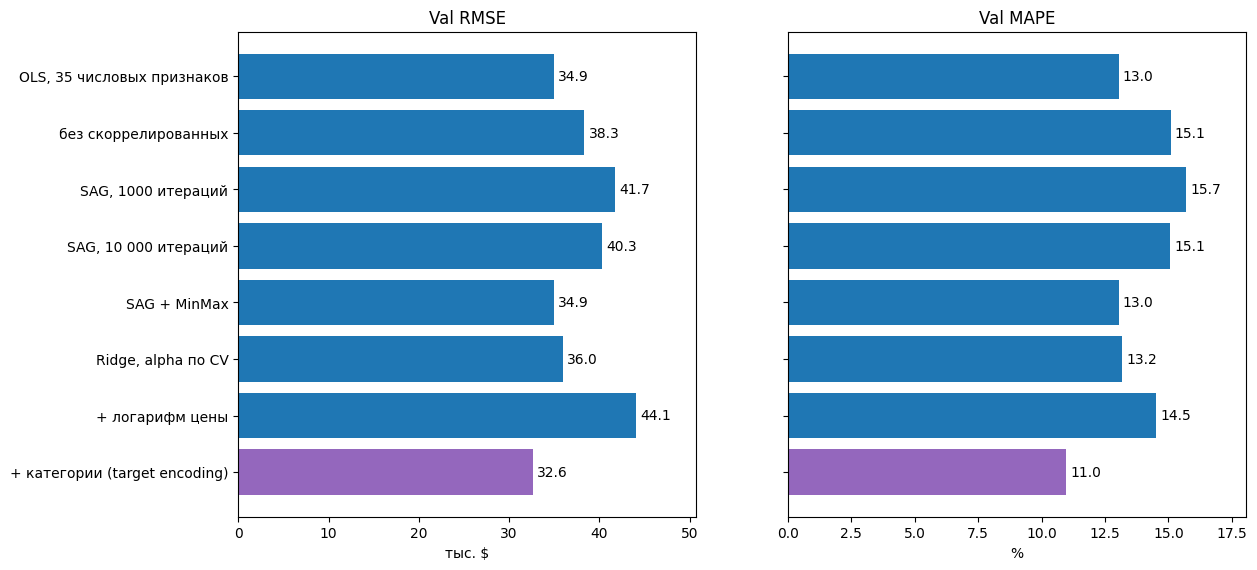

In [216]:
plot_experiments(df_res)

**Вопрос:** Можно ли по этим результатам утверждать, что модель переобучилась?

## Итоги обучения модели

Сравнили несколько способов обучения линейной регрессии:
 * стохастическую оптимизацию и влияние числа итераций на сходимость.
 * нормализацию признаков.
 * регуляризацию и подбор гиперпараметров по кросс-валидации.
 * логарифмирование целевой переменной и оценку предсказаний на исходной шкале.
 * обработку категориальных признаков без утечки целевой переменной.

Сравниваем строки итоговой таблицы по RMSE и MAPE на одной и той же валидационной выборке. Не каждый шаг обязан улучшать обе метрики: численная устойчивость, сходимость оптимизатора и качество предсказаний — разные свойства модели. Выбор преобразований и регуляризации проверяем по кросс-валидации, а получившийся результат оцениваем на отложенной выборке.

## Теперь ты умеешь

-  Бороться с проблемами, вызванными мультиколлинеарностью, с помощью:
    * численно устойчивых модификаций линейной регрессии.
    * стохастической оптимизации.
    * регуляризации.

- Применять методы обработки данных для линейной регрессии, такие как:
  * нормализация данных,
  * преобразование целевой переменной.
  * MeanTargetEncoding для кодирования категориальных признаков

- Оборачивать модели в удобные встроенные пайплайны из sklearn.

# Обратная связь по семинару для очной магистратуры

Пройди короткий опрос по [ссылке](https://polls.tbank.ru/s/cmt6wf8lr000s0ds6c5a0gedj) или QR-коду ниже.

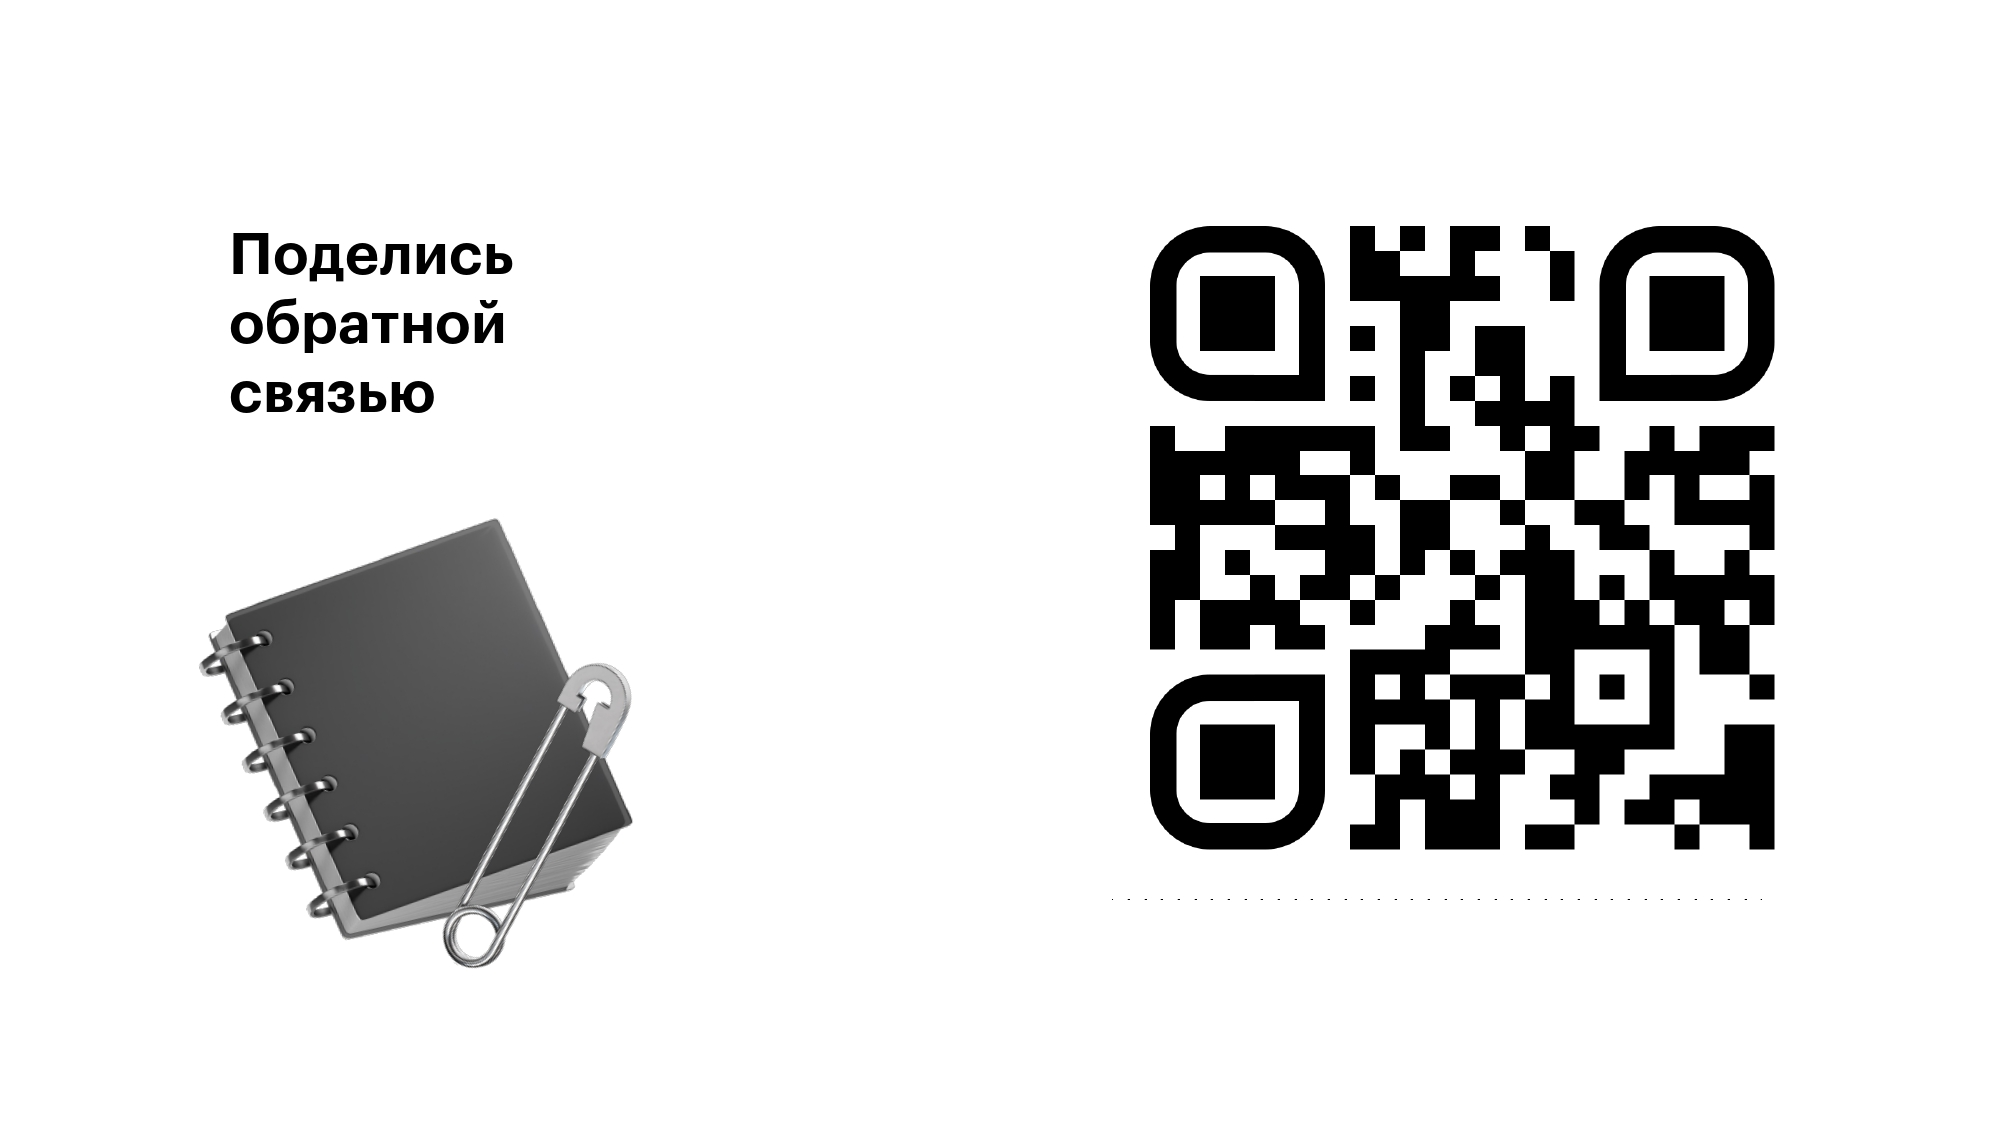

# Обратная связь по семинару для онлайн-магистратуры

Пройди короткий опрос по [ссылке](https://polls.tbank.ru/s/cms63133e00440dribvbmail8) или QR-коду ниже.

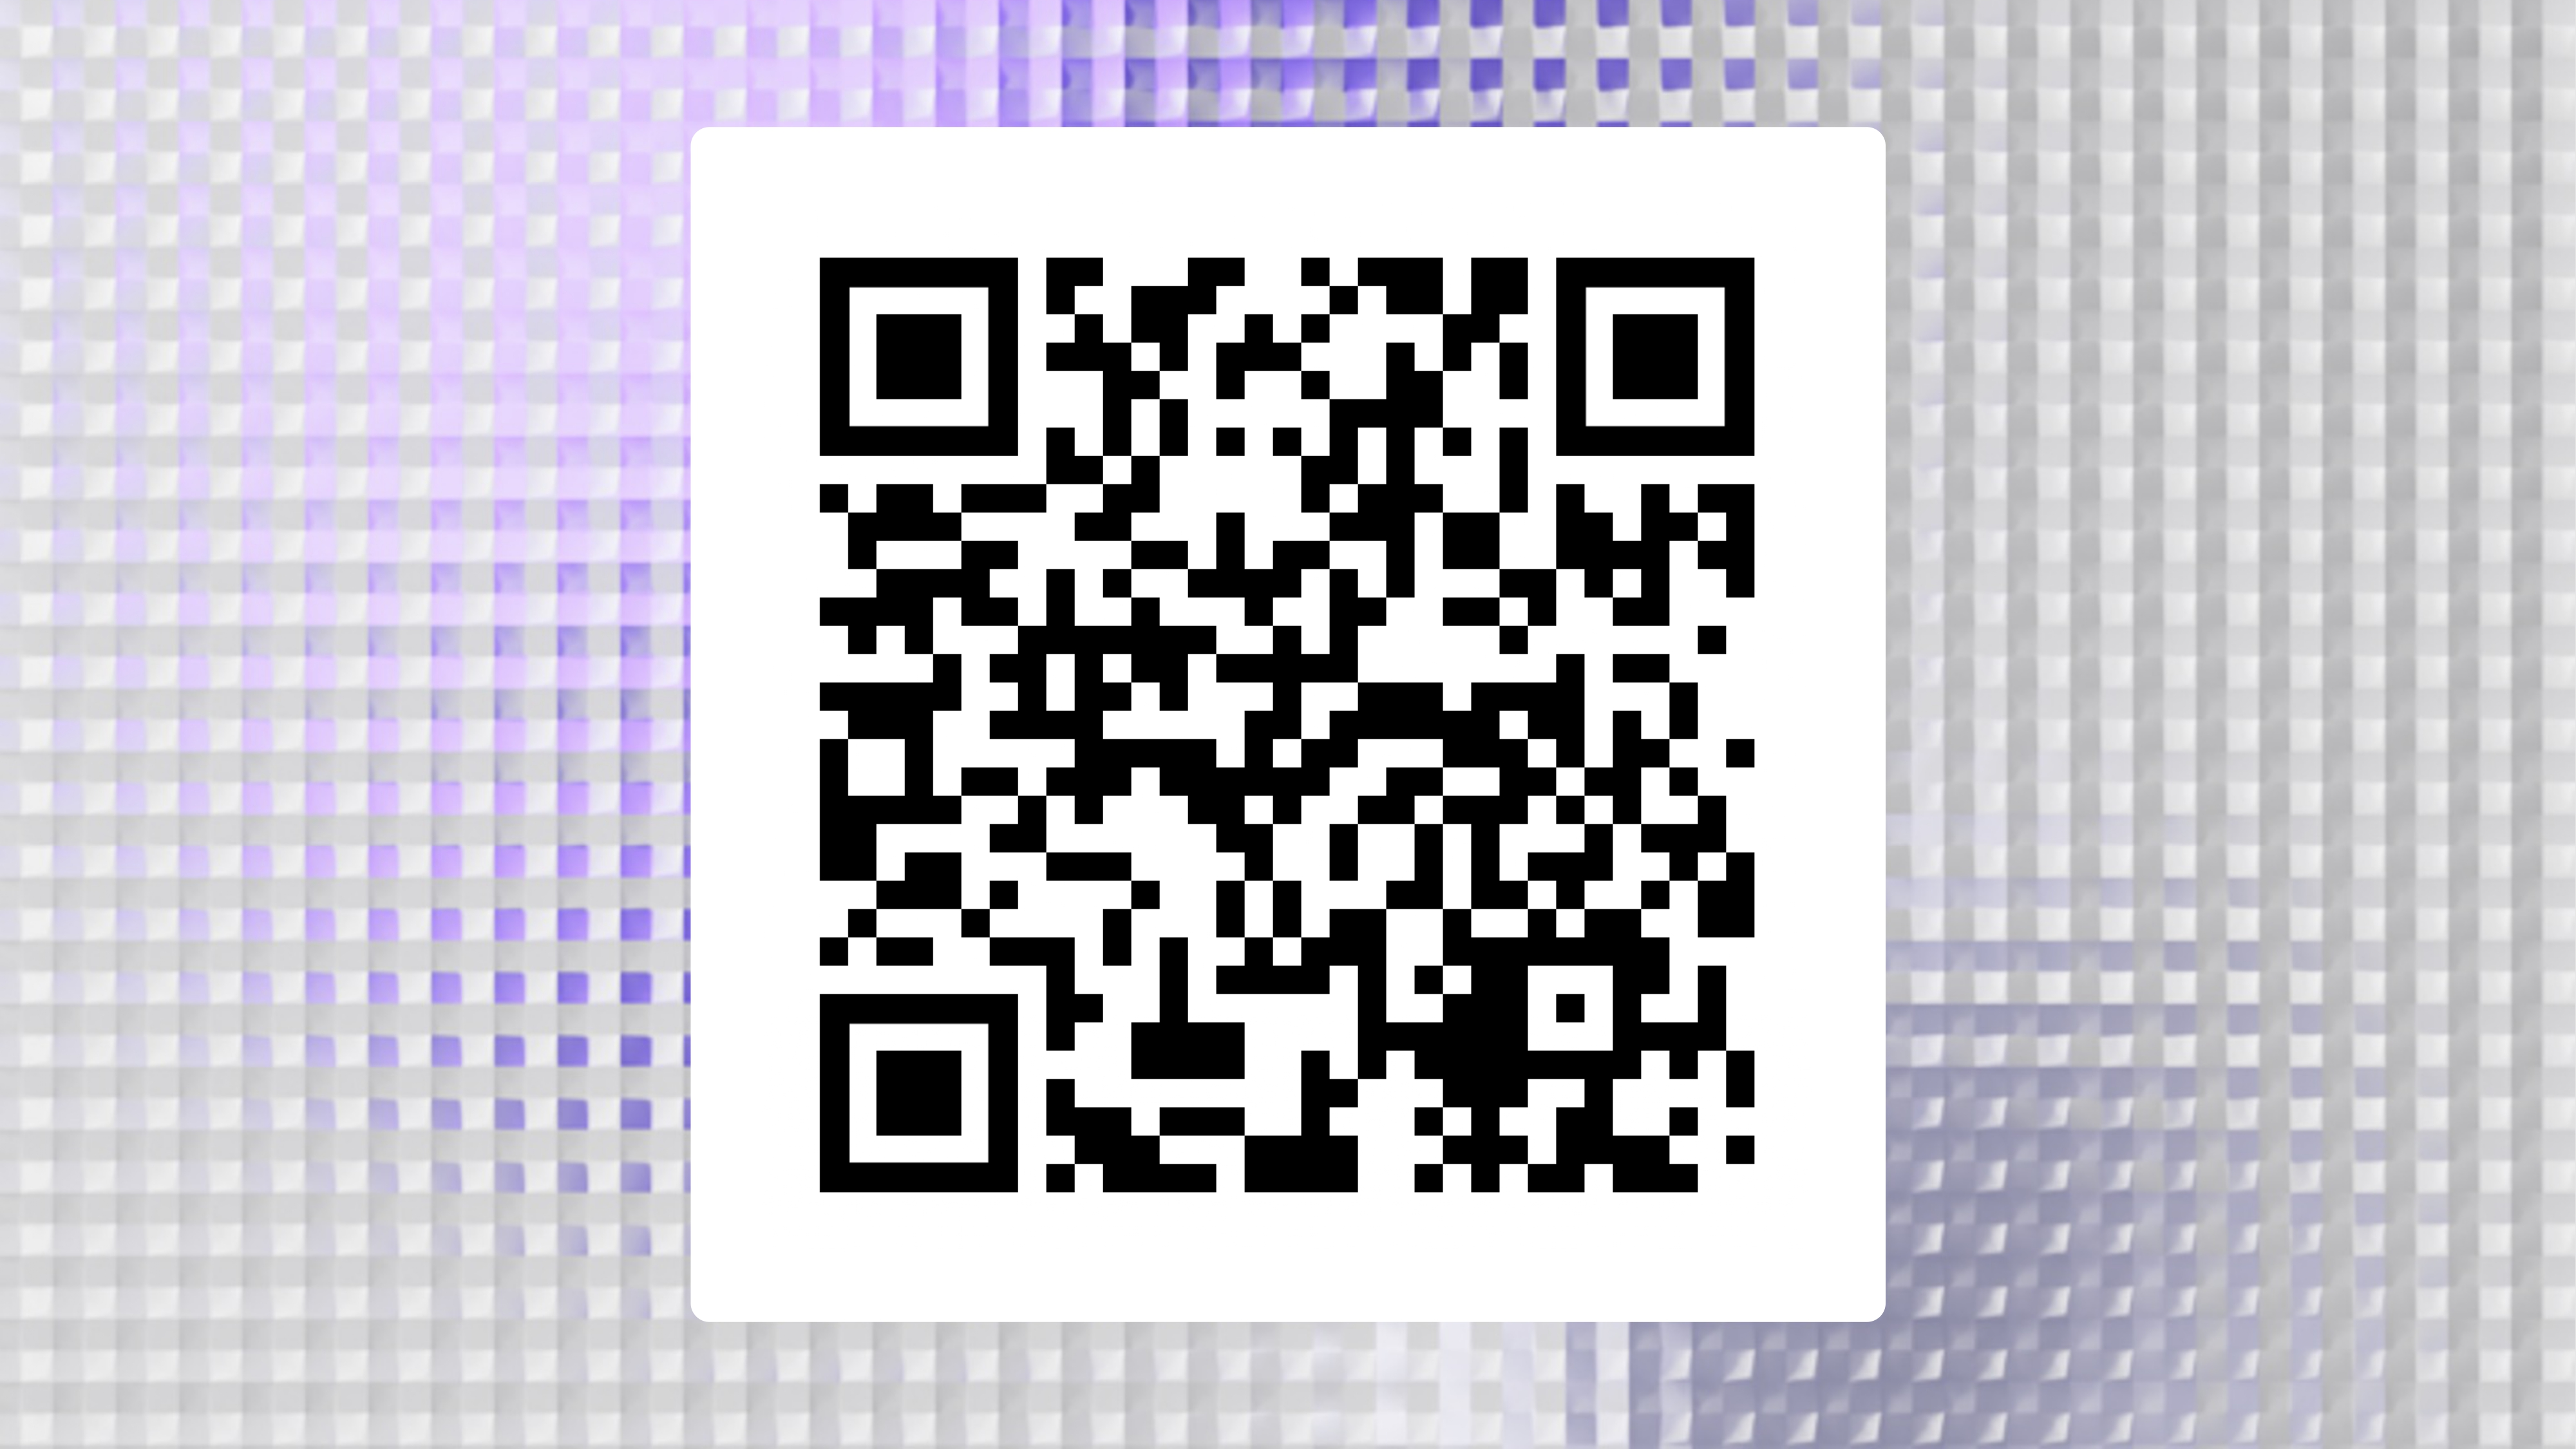